# old markdown for the explanation of older versione

# 🏆 Pokémon Battle Outcome Prediction — Competitive Type-Trajectory & Metagame Pipeline
**Course:** Fundamentals / Foundations of Data Science (Sapienza University of Rome, I Semester 2026–2027)  
**Format:** Pokémon Generation 2 OverUsed (GSC OU) — Binary Classification (`player_won` $\in \{0, 1\}$)

---

## 1. Executive Summary & Core Hypothesis

In this challenge, we must predict the final winner of a competitive Generation 2 OU Pokémon battle (`player_won`: `1` if Player 1 wins, `0` if Player 1 loses) while observing **only the first 30 active turns** of matches that last between **30 and 80 turns**. Furthermore, while we know all 6 Pokémon on Player 1's roster (`p1_team_details`), we only initially see Player 2's starting Pokémon (`p2_lead_details`) plus whichever Pokémon Player 2 reveals during the first 30 turns (`battle_timeline`).

Rather than relying solely on simple turn-30 HP snapshots—which fail when a player is setting up a late-game comeback or holding an unrevealed counter on the bench—this notebook implements a **Two-Stage Competitive Type-Trajectory & Metagame Architecture** built around four domain insights:

1. **Standardized Competitive Metagame (Internal Knowledge Mining):**  
   Because all battles take place in the competitive **Gen 2 OU** tier, team compositions and movesets are highly standardized (e.g., *Snorlax* appears in ~82% of teams, *Cloyster* in ~54%, *Zapdos* in ~52%). By mining `p1_team_details` and `battle_timeline` strictly from the training data, we construct an internal Pokédex, Pokémon usage priors, standard moveset profiles, and a **Team Type Co-occurrence Matrix** to infer the probability distribution of Player 2's unrevealed bench types.
2. **Move Effectiveness, Resistance & Setup Dynamics Drive Trainer Switching:**  
   In competitive play, trainers do not switch randomly. A trainer **stays in** if their active Pokémon resists the opponent's attack ($\le 0.5\times$), has sufficient HP to tank a hit, or acts as a **Setup / Hazard / Status** enabler (e.g., *Curse*, *Spikes*, *Rest + Sleep Talk*, *Roar/Whirlwind*). Conversely, facing a super-effective threat ($\ge 2.0\times$) forces a switch into a resistant bench type.
3. **Predicting the Next Type (Turn-31 Horizon Forecasting):**  
   Since the observation window cuts off sharply at Turn 30, knowing *who is forced to switch on Turn 31* and *which Pokémon types will take control of the field next* provides a critical lookahead signal beyond the 30-turn horizon.
4. **Whole-Team Remaining Type Dominance:**  
   Matches lasting 30–80 turns are decided by whether Player 1's surviving Pokémon types can break through Player 2's surviving + predicted hidden types using the exact Generation 2 Type Chart multipliers (`0.0x`, `0.25x`, `0.5x`, `1.0x`, `2.0x`, `4.0x`).

> **Rule Compliance Statement:**  
> This notebook strictly adheres to all competition rules:
> * **100% Classical Machine Learning:** Uses only tree-based gradient boosting and linear stacking (`LightGBM`, `XGBoost`, `CatBoost`, `LogisticRegression`). No neural networks or deep learning models are used.
> * **Zero External Data Leakage:** All usage rates, moveset profiles, and type co-occurrences are learned exclusively from the provided competition files (`train.jsonl` and `type_chart_gen2.csv`).

---

## 2. Notebook Architecture & Code Structure

The pipeline is organized into **4 modular sequential stages**:

```text
├── STEP 1: Environment Setup, Data Loading & Internal Metagame Knowledge Base
│   ├── Step 1A: Imports, constants (17 Gen-2 types), and directory path configuration
│   ├── Step 1B: Unified Data Loader (parses train.jsonl / test.jsonl / unpacked data)
│   └── Step 1C: CompetitiveMetaKnowledgeBase class (Pokedex, Usage Priors, Type Co-occurrence, Setup Profiler)
│
├── STEP 2: Turn-by-Turn Matchup Engine & Stage-1 Next-Type / Switch Predictor
│   ├── Step 2A: Turn-level feature extraction (move multipliers, expected threat, resistances, bench counters)
│   └── Step 2B: Stage-1 Auxiliary ML Models (LightGBM Switch Classifiers + Multi-Output Next-Type Classifiers)
│
├── STEP 3: Turn-31 Horizon Forecasting & Battle-Level Feature Aggregation
│   ├── Step 3A: Turn-31 Next-Type probability projection & expected type matchup matrix
│   └── Step 3B: Full 30-turn battle aggregation (HP pools, status, Spikes, momentum, remaining team type dominance)
│
└── STEP 4: Stage-2 Ensemble Training, Stratified K-Fold Validation & Submission
    ├── Step 4A: Test set (`test.jsonl`) transformation through the Step 2 & Step 3 pipelines
    ├── Step 4B: Stratified K-Fold Cross-Validation (`LightGBM` + `XGBoost` + `CatBoost`)
    └── Step 4C: Out-of-Fold (OOF) diagnostics, threshold calibration, feature importance & `submission.csv` export

In [ ]:
# ==============================================================================
# STEP 1A: IMPORTS, CONFIGURATION & FILE PATHS
# ==============================================================================
import os
import json
import numpy as np
import pandas as pd
from collections import defaultdict, Counter
import warnings
warnings.filterwarnings('ignore')

# If using Google Drive on Colab, uncomment the next two lines:
# from google.colab import drive
# drive.mount('/content/drive')

# Set your base directory path (keep the same path structure you use on Colab/Kaggle)
DATA_DIR = "/content/drive/MyDrive/1 SEMESTRE DATA SCIENCE/FUNDAMENTALS OF DATA SCIENCE/FDS PROJECT"  # Change to your Drive/Kaggle folder if needed, e.g., "/content/drive/MyDrive/FDS_Pokemon/"

TYPE_CHART_PATH = os.path.join(DATA_DIR, "type_chart_gen2.csv")
EXCEL_UNPACKED_PATH = os.path.join(DATA_DIR, "pokemon_json_spacchettato.xlsx")
TRAIN_JSONL_PATH = os.path.join(DATA_DIR, "train.jsonl")
TEST_JSONL_PATH = os.path.join(DATA_DIR, "test.jsonl")

ALL_TYPES = [
    'normal', 'fire', 'water', 'electric', 'grass', 'ice', 'fighting',
    'poison', 'ground', 'flying', 'psychic', 'bug', 'rock', 'ghost',
    'dragon', 'dark', 'steel'
]

In [ ]:
# ==============================================================================
# STEP 1B: DATA LOADER (Supports both unpacked Excel and raw JSONL)
# ==============================================================================
def load_competition_data():
    """
    Loads p1_team_details, battle_timeline, and p2_lead_details from either
    train.jsonl (if available) or pokemon_json_spacchettato.xlsx.
    """
    if os.path.exists(EXCEL_UNPACKED_PATH) and not os.path.exists(TRAIN_JSONL_PATH):
        print(f"Loading unpacked data from {EXCEL_UNPACKED_PATH}...")
        xls = pd.ExcelFile(EXCEL_UNPACKED_PATH)
        p1_team_df = pd.read_excel(xls, 'p1_team_details')
        timeline_df = pd.read_excel(xls, 'battle_timeline')
        p2_lead_df = pd.read_excel(xls, 'p2_lead_details')
        return p1_team_df, timeline_df, p2_lead_df

    elif os.path.exists(TRAIN_JSONL_PATH):
        print(f"Loading raw JSONL data from {TRAIN_JSONL_PATH}...")
        p1_rows, timeline_rows, p2_rows = [], [], []
        with open(TRAIN_JSONL_PATH, 'r') as f:
            for line in f:
                b = json.loads(line)
                b_id = b['battle_id']

                # P2 Lead & Target
                p2 = b['p2_lead_details'].copy()
                p2['battle_id'] = b_id
                p2['player_won'] = int(b['player_won'])
                p2_rows.append(p2)

                # P1 Team (6 Pokemon)
                for pkmn in b['p1_team_details']:
                    p1 = pkmn.copy()
                    p1['battle_id'] = b_id
                    p1_rows.append(p1)

                # Timeline (Up to 30 turns)
                for turn_data in b['battle_timeline']:
                    row = {'battle_id': b_id, 'turn': turn_data['turn']}
                    for side in ['p1', 'p2']:
                        state = turn_data.get(f'{side}_pokemon_state', {}) or {}
                        row[f'{side}_pokemon_state.name'] = state.get('name')
                        row[f'{side}_pokemon_state.hp_pct'] = state.get('hp_pct')
                        row[f'{side}_pokemon_state.status'] = state.get('status')
                        row[f'{side}_pokemon_state.effects'] = str(state.get('effects', 'noeffect'))
                        boosts = state.get('boosts', {}) or {}
                        for stat in ['atk', 'def', 'spa', 'spd', 'spe']:
                            row[f'{side}_pokemon_state.boosts.{stat}'] = boosts.get(stat, 0)

                        move = turn_data.get(f'{side}_move_details', {}) or {}
                        row[f'{side}_move_details.name'] = move.get('name')
                        row[f'{side}_move_details.type'] = move.get('type')
                        row[f'{side}_move_details.category'] = move.get('category')
                        row[f'{side}_move_details.base_power'] = move.get('base_power')
                        row[f'{side}_move_details.accuracy'] = move.get('accuracy')
                        row[f'{side}_move_details.priority'] = move.get('priority')
                    timeline_rows.append(row)

        return pd.DataFrame(p1_rows), pd.DataFrame(timeline_rows), pd.DataFrame(p2_rows)
    else:
        raise FileNotFoundError("Could not find pokemon_json_spacchettato.xlsx or train.jsonl!")

p1_team_df, timeline_df, p2_lead_df = load_competition_data()
type_chart_df = pd.read_csv(TYPE_CHART_PATH)

print(f"Loaded {p2_lead_df['battle_id'].nunique()} battles.")
print(f"P1 Team rows: {len(p1_team_df)} | Timeline rows: {len(timeline_df)} | P2 Lead rows: {len(p2_lead_df)}")

Loading raw JSONL data from /content/drive/MyDrive/1 SEMESTRE DATA SCIENCE/FUNDAMENTALS OF DATA SCIENCE/FDS PROJECT/train.jsonl...
Loaded 10000 battles.
P1 Team rows: 60000 | Timeline rows: 300000 | P2 Lead rows: 10000


In [ ]:
# ==============================================================================
# STEP 1C: BUILD TYPE EFFECTIVENESS ENGINE & METAGAME KNOWLEDGE BASE
# ==============================================================================
class CompetitiveMetaKnowledgeBase:
    """
    Learns strictly from training data (no external data leakage!):
    1. Exact Gen 2 Type Chart multipliers (0.0, 0.25, 0.5, 1.0, 2.0, 4.0)
    2. Internal Pokedex (maps Pokemon name -> types & base stats)
    3. Competitive Usage Priors (most used Pokemon & types in the meta)
    4. Team Type Co-occurrence Matrix (predicts remaining hidden types on P2's team)
    5. Competitive Move & Role Profiler (identifies Setup/Hazard/Status Pokemon & standard moves)
    """
    def __init__(self, type_chart_df):
        # 1. Build fast O(1) Type Multiplier Lookup
        self.type_matrix = defaultdict(lambda: defaultdict(lambda: 1.0))
        for _, row in type_chart_df.iterrows():
            atk = str(row['attacking_type']).lower().strip()
            dfd = str(row['defending_type']).lower().strip()
            self.type_matrix[atk][dfd] = float(row['multiplier'])

        self.pokedex = {}
        self.pokemon_usage_prob = {}
        self.type_usage_prob = {}
        self.type_cooccurrence = pd.DataFrame(0.0, index=ALL_TYPES, columns=ALL_TYPES)
        self.pokemon_moves_profile = defaultdict(Counter)
        self.pokemon_setup_ratio = {}

        # Define Competitive Setup, Hazard, Phazing & Recovery Moves in Gen 2 OU
        self.setup_and_support_moves = {
            'curse', 'swordsdance', 'bellydrum', 'amnesia', 'growth', 'agility', 'meditate',
            'spikes', 'toxic', 'thunderwave', 'stunspore', 'lovelykiss', 'sleeppowder',
            'hypnosis', 'spore', 'confuseray', 'attract', 'leechseed',
            'roar', 'whirlwind', 'haze', 'perishsong',
            'rest', 'sleeptalk', 'recover', 'milkdrink', 'softboiled', 'moonlight', 'synthesis',
            'reflect', 'lightscreen', 'safeguard', 'substitute', 'batonpass', 'encore', 'rapidspin'
        }

    def get_move_effectiveness(self, move_type, def_type_1, def_type_2=None):
        """Calculates exact Gen 2 damage multiplier (e.g., 0.0, 0.25, 0.5, 1.0, 2.0, 4.0)."""
        if pd.isna(move_type) or pd.isna(def_type_1):
            return 1.0
        m_type = str(move_type).lower().strip()
        t1 = str(def_type_1).lower().strip()
        mult = self.type_matrix[m_type][t1]

        if pd.notna(def_type_2) and str(def_type_2).lower().strip() not in ['nan', 'none', '']:
            t2 = str(def_type_2).lower().strip()
            mult *= self.type_matrix[m_type][t2]
        return mult

    def fit(self, p1_team_df, timeline_df, p2_lead_df):
        # A. Build Internal Pokedex from P1 full teams and P2 leads
        combined_pkmn = pd.concat([
            p1_team_df[['name', 'types', 'base_hp', 'base_atk', 'base_def', 'base_spa', 'base_spd', 'base_spe']],
            p2_lead_df[['name', 'types', 'base_hp', 'base_atk', 'base_def', 'base_spa', 'base_spd', 'base_spe']]
        ]).drop_duplicates(subset=['name'])

        for _, row in combined_pkmn.iterrows():
            raw_types = row['types']
            if isinstance(raw_types, str):
                import ast
                raw_types = ast.literal_eval(raw_types)

            # Filter out placeholder types like 'notype'
            clean_types = [t.lower().strip() for t in raw_types if t and str(t).lower().strip() not in ['notype', 'nan', 'none', '']]
            t1 = clean_types[0] if len(clean_types) > 0 else 'normal'
            t2 = clean_types[1] if len(clean_types) > 1 else None

            self.pokedex[row['name']] = {
                'type_1': t1,
                'type_2': t2,
                'types': clean_types,
                'base_hp': row['base_hp'],
                'base_atk': row['base_atk'],
                'base_def': row['base_def'],
                'base_spa': row['base_spa'],
                'base_spd': row['base_spd'],
                'base_spe': row['base_spe']
            }

        # B. Calculate Metagame Pokemon & Type Usage Frequencies (from P1 6-Pokemon teams)
        total_teams = p1_team_df['battle_id'].nunique()
        pkmn_counts = p1_team_df['name'].value_counts()
        self.pokemon_usage_prob = (pkmn_counts / total_teams).to_dict()

        type_counts = Counter()
        for _, grp in p1_team_df.groupby('battle_id'):
            team_types = set()
            for _, row in grp.iterrows():
                raw_types = row['types']
                if isinstance(raw_types, str):
                    import ast
                    raw_types = ast.literal_eval(raw_types)
                for t in raw_types:
                    t_clean = str(t).lower().strip()
                    if t_clean not in ['notype', 'nan', 'none', '']:
                        team_types.add(t_clean)
            for t in team_types:
                type_counts[t] += 1

            # C. Populate Team Type Co-occurrence Matrix
            for t_a in team_types:
                for t_b in team_types:
                    if t_a in ALL_TYPES and t_b in ALL_TYPES:
                        self.type_cooccurrence.loc[t_a, t_b] += 1.0

        self.type_usage_prob = {t: type_counts[t] / total_teams for t in ALL_TYPES}

        # Normalize Co-occurrence Matrix into Conditional Probabilities P(Type B in team | Type A in team)
        for t_a in ALL_TYPES:
            if type_counts[t_a] > 0:
                self.type_cooccurrence.loc[t_a, :] /= type_counts[t_a]

        # D. Profile Competitive Movesets & Setup vs. Offensive Roles from Timeline
        p1_moves = timeline_df[['p1_pokemon_state.name', 'p1_move_details.name', 'p1_move_details.type', 'p1_move_details.category']].dropna(subset=['p1_move_details.name'])
        p1_moves.columns = ['pokemon', 'move', 'move_type', 'category']

        p2_moves = timeline_df[['p2_pokemon_state.name', 'p2_move_details.name', 'p2_move_details.type', 'p2_move_details.category']].dropna(subset=['p2_move_details.name'])
        p2_moves.columns = ['pokemon', 'move', 'move_type', 'category']

        all_moves = pd.concat([p1_moves, p2_moves])

        setup_counts = Counter()
        total_move_counts = Counter()

        for _, row in all_moves.iterrows():
            pkmn = row['pokemon']
            mv = str(row['move']).lower().strip()
            self.pokemon_moves_profile[pkmn][mv] += 1
            total_move_counts[pkmn] += 1
            if mv in self.setup_and_support_moves or str(row['category']).lower() == 'status':
                setup_counts[pkmn] += 1

        for pkmn in total_move_counts:
            self.pokemon_setup_ratio[pkmn] = setup_counts[pkmn] / total_move_counts[pkmn]

        return self

    def predict_remaining_team_type_probs(self, revealed_pokemon_names):
        """
        Given the Pokemon revealed so far by a player, predicts the probability distribution
        of the remaining hidden types on their bench using competitive team co-occurrence.
        """
        revealed_types = set()
        for name in revealed_pokemon_names:
            if name in self.pokedex:
                revealed_types.update(self.pokedex[name]['types'])

        if not revealed_types:
            return self.type_usage_prob.copy()

        # Average conditional probability P(Target Type | Revealed Types)
        cond_probs = self.type_cooccurrence.loc[list(revealed_types), :].mean(axis=0).to_dict()
        return cond_probs

# Instantiate and fit our Knowledge Base on the dataset
meta_kb = CompetitiveMetaKnowledgeBase(type_chart_df).fit(p1_team_df, timeline_df, p2_lead_df)

# Sanity Check Output
print("=== TOP 10 MOST USED COMPETITIVE POKEMON (P(In Team)) ===")
for pkmn, prob in list(meta_kb.pokemon_usage_prob.items())[:10]:
    setup_pct = meta_kb.pokemon_setup_ratio.get(pkmn, 0.0) * 100
    top_moves = [m for m, _ in meta_kb.pokemon_moves_profile[pkmn].most_common(4)]
    print(f"- {pkmn.capitalize():<12} | Team Usage: {prob*100:5.1f}% | Setup/Support Role: {setup_pct:4.1f}% | Standard Moves: {top_moves}")

print("\n=== TOP 8 MOST USED TYPES ACROSS TEAMS ===")
for t, prob in sorted(meta_kb.type_usage_prob.items(), key=lambda x: x[1], reverse=True)[:8]:
    print(f"- {t.capitalize():<10}: present in {prob*100:5.1f}% of competitive teams")

=== TOP 10 MOST USED COMPETITIVE POKEMON (P(In Team)) ===
- Snorlax      | Team Usage:  82.2% | Setup/Support Role: 42.9% | Standard Moves: ['doubleedge', 'curse', 'bodyslam', 'rest']
- Cloyster     | Team Usage:  54.1% | Setup/Support Role: 62.2% | Standard Moves: ['spikes', 'surf', 'toxic', 'explosion']
- Zapdos       | Team Usage:  50.0% | Setup/Support Role: 28.0% | Standard Moves: ['thunder', 'hiddenpower', 'sleeptalk', 'thunderbolt']
- Raikou       | Team Usage:  31.8% | Setup/Support Role: 38.4% | Standard Moves: ['thunder', 'thunderbolt', 'hiddenpower', 'roar']
- Tyranitar    | Team Usage:  26.9% | Setup/Support Role: 19.5% | Standard Moves: ['rockslide', 'pursuit', 'roar', 'earthquake']
- Exeggutor    | Team Usage:  26.2% | Setup/Support Role: 38.7% | Standard Moves: ['psychic', 'sleeppowder', 'stunspore', 'gigadrain']
- Gengar       | Team Usage:  26.0% | Setup/Support Role: 21.1% | Standard Moves: ['icepunch', 'thunderbolt', 'dynamicpunch', 'hypnosis']
- Skarmory     | Team 

# section 2


In [ ]:
# ==============================================================================
# STEP 2 (V2): UPGRADED TURN ENGINE WITH GEN-2 STAT/STAB DAMAGE & COUNTER MATRIX
# ==============================================================================
# Gen 2 Physical vs Special Type Split
PHYSICAL_TYPES = {'normal', 'fighting', 'flying', 'ground', 'rock', 'bug', 'ghost', 'poison', 'steel'}
SPECIAL_TYPES  = {'fire', 'water', 'grass', 'electric', 'psychic', 'ice', 'dragon', 'dark'}

def get_boost_multiplier(stage):
    """Converts Gen 2 stat stage (-6 to +6) into its exact combat multiplier."""
    stage = max(-6, min(6, int(stage)))
    return (2.0 + stage) / 2.0 if stage >= 0 else 2.0 / (2.0 - stage)

def extract_clean_types(types_val):
    if isinstance(types_val, (list, tuple, set)):
        return [str(t).lower().strip() for t in types_val if str(t).lower().strip() not in ['nan', 'none', 'notype', '']]
    elif pd.notna(types_val):
        t_str = str(types_val).lower().strip()
        if t_str not in ['nan', 'none', 'notype', '']:
            return [t_str]
    return []

def get_type_multiplier_from_list(meta_kb, move_type, def_types):
    if pd.isna(move_type) or not def_types:
        return 1.0
    m_type = str(move_type).lower().strip()
    if m_type in ['nan', 'none', 'threequestionmarks', '']:
        return 1.0
    mult = 1.0
    for dt in def_types:
        mult *= meta_kb.type_matrix[m_type][dt]
    return mult

def estimate_gen2_duel_threat(meta_kb, atk_name, atk_types, def_name, def_types, atk_boosts=None, def_boosts=None):
    """
    Computes best expected Gen 2 damage power between two Pokemon considering:
    - Attacker's STAB types + known competitive coverage move types
    - Gen 2 Physical/Special split (Base Atk vs Def, Base SpA vs SpD)
    - Active stat stage boosts (+1 Curse, +2 Swords Dance, etc.)
    - Exact Gen 2 Type Chart multiplier
    """
    if not def_types:
        return 1.0
    atk_info = meta_kb.pokedex.get(atk_name, {})
    def_info = meta_kb.pokedex.get(def_name, {})

    b_atk = atk_info.get('base_atk', 85) * get_boost_multiplier((atk_boosts or {}).get('atk', 0))
    b_spa = atk_info.get('base_spa', 85) * get_boost_multiplier((atk_boosts or {}).get('spa', 0))
    b_def = max(20.0, def_info.get('base_def', 85) * get_boost_multiplier((def_boosts or {}).get('def', 0)))
    b_spd = max(20.0, def_info.get('base_spd', 85) * get_boost_multiplier((def_boosts or {}).get('spd', 0)))

    candidate_types = set(atk_types)
    # Add common coverage move types for top meta Pokemon if known
    if not candidate_types:
        candidate_types = {'normal'}

    best_damage_index = 0.5
    for m_type in candidate_types:
        type_mult = get_type_multiplier_from_list(meta_kb, m_type, def_types)
        stab = 1.5 if m_type in atk_types else 1.0
        if m_type in PHYSICAL_TYPES:
            stat_ratio = b_atk / b_def
        else:
            stat_ratio = b_spa / b_spd
        best_damage_index = max(best_damage_index, type_mult * stab * stat_ratio)

    return best_damage_index

# Ensure Pokedex in meta_kb has clean types from the 'types' list column
for _, row in pd.concat([p1_team_df, p2_lead_df], ignore_index=True).drop_duplicates(subset=['name']).iterrows():
    p_types = extract_clean_types(row['types']) if 'types' in row else extract_clean_types([row.get('type_1'), row.get('type_2')])
    meta_kb.pokedex[row['name']] = {
        'types': p_types,
        'base_hp': float(row['base_hp']),
        'base_atk': float(row['base_atk']),
        'base_def': float(row['base_def']),
        'base_spa': float(row['base_spa']),
        'base_spd': float(row['base_spd']),
        'base_spe': float(row['base_spe']),
    }

print("Updated Pokedex with Gen 2 Physical/Special combat stats for", len(meta_kb.pokedex), "Pokemon.")

Updated Pokedex with Gen 2 Physical/Special combat stats for 239 Pokemon.


# step 3


In [ ]:
# ==============================================================================
# STEP 3 (V5 - SELF-CONTAINED): TURN ENGINE, TURN-31 FORECAST & FULL V5 FEATURES
# ==============================================================================
from sklearn.multioutput import MultiOutputClassifier
from lightgbm import LGBMClassifier

PHYSICAL_TYPES = {'normal', 'fighting', 'flying', 'ground', 'rock', 'bug', 'ghost', 'poison', 'steel'}
SPECIAL_TYPES  = {'fire', 'water', 'grass', 'electric', 'psychic', 'ice', 'dragon', 'dark'}

P1_NEXT_TYPE_TARGETS = [f'target_p1_next_type_{t}' for t in ALL_TYPES]
P2_NEXT_TYPE_TARGETS = [f'target_p2_next_type_{t}' for t in ALL_TYPES]

def get_boost_multiplier(stage):
    stage = max(-6, min(6, int(stage)))
    return (2.0 + stage) / 2.0 if stage >= 0 else 2.0 / (2.0 - stage)

def extract_clean_types(types_val):
    if isinstance(types_val, (list, tuple, set)):
        return [str(t).lower().strip() for t in types_val if str(t).lower().strip() not in ['nan', 'none', 'notype', '']]
    elif pd.notna(types_val):
        t_str = str(types_val).lower().strip()
        if t_str not in ['nan', 'none', 'notype', '']:
            return [t_str]
    return []

def get_type_multiplier_from_list(meta_kb, move_type, def_types):
    if pd.isna(move_type) or not def_types:
        return 1.0
    m_type = str(move_type).lower().strip()
    if m_type in ['nan', 'none', 'threequestionmarks', '']:
        return 1.0
    mult = 1.0
    for dt in def_types:
        mult *= meta_kb.type_matrix[m_type][dt]
    return mult

def estimate_gen2_duel_threat(meta_kb, atk_name, atk_types, def_name, def_types, atk_boosts=None, def_boosts=None):
    if not def_types:
        return 1.0
    atk_info = meta_kb.pokedex.get(atk_name, {})
    def_info = meta_kb.pokedex.get(def_name, {})
    b_atk = atk_info.get('base_atk', 85) * get_boost_multiplier((atk_boosts or {}).get('atk', 0))
    b_spa = atk_info.get('base_spa', 85) * get_boost_multiplier((atk_boosts or {}).get('spa', 0))
    b_def = max(20.0, def_info.get('base_def', 85) * get_boost_multiplier((def_boosts or {}).get('def', 0)))
    b_spd = max(20.0, def_info.get('base_spd', 85) * get_boost_multiplier((def_boosts or {}).get('spd', 0)))
    candidate_types = set(atk_types) if atk_types else {'normal'}
    best_damage_index = 0.5
    for m_type in candidate_types:
        type_mult = get_type_multiplier_from_list(meta_kb, m_type, def_types)
        stab = 1.5 if m_type in atk_types else 1.0
        stat_ratio = (b_atk / b_def) if m_type in PHYSICAL_TYPES else (b_spa / b_spd)
        best_damage_index = max(best_damage_index, type_mult * stab * stat_ratio)
    return best_damage_index

# Ensure Pokedex in meta_kb has clean types and combat stats
for _, row in pd.concat([p1_team_df, p2_lead_df], ignore_index=True).drop_duplicates(subset=['name']).iterrows():
    p_types = extract_clean_types(row['types']) if 'types' in row else extract_clean_types([row.get('type_1'), row.get('type_2')])
    meta_kb.pokedex[row['name']] = {
        'types': p_types,
        'base_hp': float(row['base_hp']),
        'base_atk': float(row['base_atk']),
        'base_def': float(row['base_def']),
        'base_spa': float(row['base_spa']),
        'base_spd': float(row['base_spd']),
        'base_spe': float(row['base_spe']),
    }

# 1. Turn-Level Feature Builder (Defines turn_df!)
def build_turn_level_dataset_v2(p1_team_df, timeline_df, meta_kb):
    p1_rosters = defaultdict(dict)
    for _, row in p1_team_df.iterrows():
        b_id = row['battle_id']
        name = row['name']
        p_types = extract_clean_types(row['types']) if 'types' in row else extract_clean_types([row.get('type_1'), row.get('type_2')])
        p1_rosters[b_id][name] = p_types

    timeline_sorted = timeline_df.sort_values(['battle_id', 'turn']).reset_index(drop=True)
    turn_records = []

    for b_id, group in timeline_sorted.groupby('battle_id', sort=False):
        rows = group.to_dict('records')
        n_turns = len(rows)
        p1_roster = p1_rosters[b_id]
        p1_hp_tracker = {name: 1.0 for name in p1_roster}
        p2_revealed_set = set()
        p2_hp_tracker = {}

        for i, row in enumerate(rows):
            p1_name, p2_name = row['p1_pokemon_state.name'], row['p2_pokemon_state.name']
            p1_hp, p2_hp = float(row['p1_pokemon_state.hp_pct']), float(row['p2_pokemon_state.hp_pct'])
            p1_hp_tracker[p1_name], p2_hp_tracker[p2_name] = p1_hp, p2_hp
            p2_revealed_set.add(p2_name)

            p1_types = meta_kb.pokedex.get(p1_name, {}).get('types', p1_roster.get(p1_name, []))
            p2_types = meta_kb.pokedex.get(p2_name, {}).get('types', [])

            p1_boosts = {s: int(row.get(f'p1_pokemon_state.boosts.{s}', 0)) for s in ['atk', 'def', 'spa', 'spd', 'spe']}
            p2_boosts = {s: int(row.get(f'p2_pokemon_state.boosts.{s}', 0)) for s in ['atk', 'def', 'spa', 'spd', 'spe']}

            p1_move_type, p2_move_type = row.get('p1_move_details.type'), row.get('p2_move_details.type')
            p1_bp = float(row.get('p1_move_details.base_power') or 0.0)
            p2_bp = float(row.get('p2_move_details.base_power') or 0.0)

            p1_move_eff_on_p2 = get_type_multiplier_from_list(meta_kb, p1_move_type, p2_types)
            p2_move_eff_on_p1 = get_type_multiplier_from_list(meta_kb, p2_move_type, p1_types)

            p1_expected_threat_on_p2 = estimate_gen2_duel_threat(meta_kb, p1_name, p1_types, p2_name, p2_types, p1_boosts, p2_boosts)
            p2_expected_threat_on_p1 = estimate_gen2_duel_threat(meta_kb, p2_name, p2_types, p1_name, p1_types, p2_boosts, p1_boosts)

            p1_boost_sum, p2_boost_sum = sum(p1_boosts.values()), sum(p2_boosts.values())
            p1_setup_role = meta_kb.pokemon_setup_ratio.get(p1_name, 0.0)
            p2_setup_role = meta_kb.pokemon_setup_ratio.get(p2_name, 0.0)

            p1_resists_p2 = int(p2_move_eff_on_p1 <= 0.5 or p2_expected_threat_on_p1 <= 0.75)
            p2_resists_p1 = int(p1_move_eff_on_p2 <= 0.5 or p1_expected_threat_on_p2 <= 0.75)

            p1_can_tank_and_stay = int((p1_hp >= 0.55 and p2_expected_threat_on_p1 <= 1.2) or p1_resists_p2 == 1 or p1_boost_sum > 0)
            p2_can_tank_and_stay = int((p2_hp >= 0.55 and p1_expected_threat_on_p2 <= 1.2) or p2_resists_p1 == 1 or p2_boost_sum > 0)

            p1_bench_resist_count = 0
            p1_alive_bench_types = set()
            for b_name, b_types in p1_roster.items():
                if b_name != p1_name and p1_hp_tracker.get(b_name, 1.0) > 0.0:
                    p1_alive_bench_types.update(b_types)
                    if estimate_gen2_duel_threat(meta_kb, p2_name, p2_types, b_name, b_types) <= 0.8:
                        p1_bench_resist_count += 1

            p2_rem_type_probs = meta_kb.predict_remaining_team_type_probs(p2_revealed_set)
            p2_known_bench_types = set()
            for rev_name in p2_revealed_set:
                if rev_name != p2_name and p2_hp_tracker.get(rev_name, 1.0) > 0.0:
                    p2_known_bench_types.update(meta_kb.pokedex.get(rev_name, {}).get('types', []))

            p1_spe = meta_kb.pokedex.get(p1_name, {}).get('base_spe', 80) * get_boost_multiplier(p1_boosts['spe'])
            p2_spe = meta_kb.pokedex.get(p2_name, {}).get('base_spe', 80) * get_boost_multiplier(p2_boosts['spe'])
            if str(row.get('p1_pokemon_state.status')) == 'par': p1_spe *= 0.25
            if str(row.get('p2_pokemon_state.status')) == 'par': p2_spe *= 0.25
            spe_advantage = p1_spe - p2_spe

            rec = {
                'battle_id': b_id, 'turn': row['turn'],
                'p1_hp': p1_hp, 'p2_hp': p2_hp, 'p1_bp': p1_bp, 'p2_bp': p2_bp,
                'p1_move_eff_on_p2': p1_move_eff_on_p2, 'p2_move_eff_on_p1': p2_move_eff_on_p1,
                'p1_expected_threat_on_p2': p1_expected_threat_on_p2, 'p2_expected_threat_on_p1': p2_expected_threat_on_p1,
                'net_duel_threat': p1_expected_threat_on_p2 - p2_expected_threat_on_p1,
                'p1_resists_p2': p1_resists_p2, 'p2_resists_p1': p2_resists_p1,
                'p1_boost_sum': p1_boost_sum, 'p2_boost_sum': p2_boost_sum,
                'p1_setup_role': p1_setup_role, 'p2_setup_role': p2_setup_role,
                'p1_can_tank_and_stay': p1_can_tank_and_stay, 'p2_can_tank_and_stay': p2_can_tank_and_stay,
                'p1_bench_resist_count': p1_bench_resist_count, 'p2_revealed_count': len(p2_revealed_set),
                'spe_advantage': spe_advantage, 'p1_is_faster': int(spe_advantage > 0),
            }

            for t in ALL_TYPES:
                rec[f'p1_active_type_{t}'] = int(t in p1_types)
                rec[f'p2_active_type_{t}'] = int(t in p2_types)
                rec[f'p1_bench_has_{t}'] = int(t in p1_alive_bench_types)
                rec[f'p2_rem_prob_{t}'] = 1.0 if (t in p2_known_bench_types) else p2_rem_type_probs.get(t, 0.0)

            if i < n_turns - 1:
                next_p1_name, next_p2_name = rows[i + 1]['p1_pokemon_state.name'], rows[i + 1]['p2_pokemon_state.name']
                next_p1_types = meta_kb.pokedex.get(next_p1_name, {}).get('types', p1_roster.get(next_p1_name, []))
                next_p2_types = meta_kb.pokedex.get(next_p2_name, {}).get('types', [])
                rec['has_next_turn'] = 1
                rec['target_p1_switched'] = int(next_p1_name != p1_name)
                rec['target_p2_switched'] = int(next_p2_name != p2_name)
                for t in ALL_TYPES:
                    rec[f'target_p1_next_type_{t}'] = int(t in next_p1_types)
                    rec[f'target_p2_next_type_{t}'] = int(t in next_p2_types)
            else:
                rec['has_next_turn'] = 0

            turn_records.append(rec)

    return pd.DataFrame(turn_records)

TURN_FEATURE_COLS = [
    'turn', 'p1_hp', 'p2_hp', 'p1_bp', 'p2_bp',
    'p1_move_eff_on_p2', 'p2_move_eff_on_p1',
    'p1_expected_threat_on_p2', 'p2_expected_threat_on_p1', 'net_duel_threat',
    'p1_resists_p2', 'p2_resists_p1',
    'p1_boost_sum', 'p2_boost_sum',
    'p1_setup_role', 'p2_setup_role',
    'p1_can_tank_and_stay', 'p2_can_tank_and_stay',
    'p1_bench_resist_count', 'p2_revealed_count', 'spe_advantage', 'p1_is_faster'
] + [f'p1_active_type_{t}' for t in ALL_TYPES] \
  + [f'p2_active_type_{t}' for t in ALL_TYPES] \
  + [f'p1_bench_has_{t}' for t in ALL_TYPES] \
  + [f'p2_rem_prob_{t}' for t in ALL_TYPES]

# Build turn_df and train Stage-1 models if not already in memory
if 'turn_df' not in globals() or 'net_duel_threat' not in turn_df.columns:
    print("Building turn_df and training Stage-1 Switch & Next-Type models...")
    turn_df = build_turn_level_dataset_v2(p1_team_df, timeline_df, meta_kb)
    train_turns = turn_df[turn_df['has_next_turn'] == 1].reset_index(drop=True)
    X_turns = train_turns[TURN_FEATURE_COLS]

    p1_switch_model = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, subsample_for_bin=50000, random_state=42, verbose=-1)
    p2_switch_model = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, subsample_for_bin=50000, random_state=42, verbose=-1)
    p1_switch_model.fit(X_turns, train_turns['target_p1_switched'])
    p2_switch_model.fit(X_turns, train_turns['target_p2_switched'])

    p1_switch_mask = train_turns['target_p1_switched'] == 1
    p2_switch_mask = train_turns['target_p2_switched'] == 1
    p1_next_type_model = MultiOutputClassifier(LGBMClassifier(n_estimators=120, learning_rate=0.05, num_leaves=15, random_state=42, verbose=-1))
    p2_next_type_model = MultiOutputClassifier(LGBMClassifier(n_estimators=120, learning_rate=0.05, num_leaves=15, random_state=42, verbose=-1))
    p1_next_type_model.fit(X_turns[p1_switch_mask], train_turns.loc[p1_switch_mask, P1_NEXT_TYPE_TARGETS])
    p2_next_type_model.fit(X_turns[p2_switch_mask], train_turns.loc[p2_switch_mask, P2_NEXT_TYPE_TARGETS])

def extract_multioutput_probs(multi_model, X_df):
    preds_list = multi_model.predict_proba(X_df)
    prob_matrix = np.zeros((len(X_df), len(ALL_TYPES)))
    for idx, p in enumerate(preds_list):
        prob_matrix[:, idx] = p[:, 1] if p.shape[1] > 1 else 0.0
    return prob_matrix

def compute_turn31_expected_type_features_v2(turn_df, meta_kb, p1_sw_mod, p2_sw_mod, p1_nt_mod, p2_nt_mod):
    last_turns = turn_df.sort_values(['battle_id', 'turn']).groupby('battle_id', as_index=False).last()
    X_last = last_turns[TURN_FEATURE_COLS]

    p1_sw_prob = p1_sw_mod.predict_proba(X_last)[:, 1]
    p2_sw_prob = p2_sw_mod.predict_proba(X_last)[:, 1]
    p1_switch_type_probs = extract_multioutput_probs(p1_nt_mod, X_last)
    p2_switch_type_probs = extract_multioutput_probs(p2_nt_mod, X_last)

    p1_curr_types = last_turns[[f'p1_active_type_{t}' for t in ALL_TYPES]].values
    p2_curr_types = last_turns[[f'p2_active_type_{t}' for t in ALL_TYPES]].values

    p1_t31_type_probs = (1.0 - p1_sw_prob[:, None]) * p1_curr_types + p1_sw_prob[:, None] * p1_switch_type_probs
    p2_t31_type_probs = (1.0 - p2_sw_prob[:, None]) * p2_curr_types + p2_sw_prob[:, None] * p2_switch_type_probs

    M = np.ones((len(ALL_TYPES), len(ALL_TYPES)))
    for i, atk_t in enumerate(ALL_TYPES):
        for j, def_t in enumerate(ALL_TYPES):
            M[i, j] = meta_kb.type_matrix[atk_t][def_t]

    p1_t31_expected_offense = np.einsum('bi,ij,bj->b', p1_t31_type_probs, M, p2_t31_type_probs)
    p2_t31_expected_offense = np.einsum('bi,ij,bj->b', p2_t31_type_probs, M, p1_t31_type_probs)
    p1_vs_p2_switch_mult = np.einsum('bi,ij,bj->b', p1_curr_types, M, p2_switch_type_probs)
    p2_vs_p1_switch_mult = np.einsum('bi,ij,bj->b', p2_curr_types, M, p1_switch_type_probs)

    t31_df = pd.DataFrame({
        'battle_id': last_turns['battle_id'].values,
        't31_p1_switch_prob': p1_sw_prob,
        't31_p2_switch_prob': p2_sw_prob,
        't31_switch_prob_diff': p2_sw_prob - p1_sw_prob,
        't31_p1_expected_type_mult': p1_t31_expected_offense,
        't31_p2_expected_type_mult': p2_t31_expected_offense,
        't31_net_type_advantage': p1_t31_expected_offense - p2_t31_expected_offense,
        't31_p1_punish_switch_mult': p1_vs_p2_switch_mult,
        't31_p2_punish_switch_mult': p2_vs_p1_switch_mult,
        't30_active_net_duel_threat': last_turns['net_duel_threat'].values,
        't30_active_spe_advantage': last_turns['spe_advantage'].values,
        't30_p1_hp': last_turns['p1_hp'].values,
        't30_p2_hp': last_turns['p2_hp'].values,
        't30_active_hp_diff': last_turns['p1_hp'].values - last_turns['p2_hp'].values,
    })

    KEY_META_TYPES = ['normal', 'water', 'electric', 'steel', 'ground', 'rock', 'fighting', 'psychic', 'ghost', 'fire', 'ice']
    for t in KEY_META_TYPES:
        idx = ALL_TYPES.index(t)
        t31_df[f't31_p2_pred_type_{t}'] = p2_t31_type_probs[:, idx]
        t31_df[f't31_p1_pred_type_{t}'] = p1_t31_type_probs[:, idx]

    return t31_df, M

# 2. Full Battle-Level Feature Extractor (Combines V3 + V4 Multiplicative Type + V5 Unlogged P2 KO Detector!)
def build_full_v5_battle_dataset(p1_team_df, timeline_df, p2_lead_df, turn_df, t31_df, meta_kb):
    p1_team_info = defaultdict(dict)
    for _, row in p1_team_df.iterrows():
        b_id = row['battle_id']
        name = row['name']
        lvl = float(row.get('level', 100.0))
        item = str(row.get('item', '')).lower().strip()
        p_types = extract_clean_types(row['types']) if 'types' in row else extract_clean_types([row.get('type_1'), row.get('type_2')])
        eff_atk = float(row['base_atk']) * (2.0 if item == 'thickclub' else 1.0)
        bst = (float(row['base_hp']) + eff_atk + float(row['base_def']) +
               float(row['base_spa']) + float(row['base_spd']) + float(row['base_spe'])) * (lvl / 100.0)
        p1_team_info[b_id][name] = {
            'types': p_types, 'level': lvl, 'item': item, 'bst': bst,
            'usage': meta_kb.pokemon_usage_prob.get(name, 0.0),
            'setup_role': meta_kb.pokemon_setup_ratio.get(name, 0.0),
            'base_spe': float(row['base_spe']) * (lvl / 100.0)
        }

    turn_grp = turn_df.groupby('battle_id').agg(
        p1_mean_move_eff=('p1_move_eff_on_p2', 'mean'),
        p2_mean_move_eff=('p2_move_eff_on_p1', 'mean'),
        p1_se_turns=('p1_move_eff_on_p2', lambda s: (s >= 2.0).sum()),
        p2_se_turns=('p2_move_eff_on_p1', lambda s: (s >= 2.0).sum()),
        p1_resist_turns=('p1_resists_p2', 'sum'),
        p2_resist_turns=('p2_resists_p1', 'sum'),
        p1_tank_stay_turns=('p1_can_tank_and_stay', 'sum'),
        p2_tank_stay_turns=('p2_can_tank_and_stay', 'sum'),
        p1_mean_exp_threat=('p1_expected_threat_on_p2', 'mean'),
        p2_mean_exp_threat=('p2_expected_threat_on_p1', 'mean'),
        mean_net_duel_threat=('net_duel_threat', 'mean'),
        mean_spe_advantage=('spe_advantage', 'mean'),
        p1_faster_turns=('p1_is_faster', 'sum'),
        last_p1_bench_resist=('p1_bench_resist_count', 'last'),
    ).reset_index()

    late_turns = turn_df[turn_df['turn'] >= 21].groupby('battle_id').agg(
        late_net_duel_threat=('net_duel_threat', 'mean'),
        late_p1_se_turns=('p1_move_eff_on_p2', lambda s: (s >= 2.0).sum()),
        late_p2_se_turns=('p2_move_eff_on_p1', lambda s: (s >= 2.0).sum()),
        late_spe_advantage=('spe_advantage', 'mean'),
    ).reset_index()

    very_late_turns = turn_df[turn_df['turn'] >= 26].groupby('battle_id').agg(
        vlate_net_duel_threat=('net_duel_threat', 'mean'),
        vlate_p1_faster=('p1_is_faster', 'mean'),
    ).reset_index()

    STATUS_SEVERITY = {'fnt': 1.0, 'frz': 0.85, 'slp': 0.65, 'tox': 0.45, 'brn': 0.40, 'par': 0.35, 'psn': 0.25, 'nostatus': 0.0}
    RECOVERY_MOVES = {'rest', 'recover', 'milkdrink', 'softboiled', 'moonlight', 'synthesis', 'morningsun', 'painsplit'}
    PHAZING_MOVES = {'roar', 'whirlwind'}
    BOOM_MOVES = {'explosion', 'selfdestruct', 'destinybond'}
    CLERIC_MOVES = {'healbell'}
    SPIN_MOVES = {'rapidspin'}
    TRAP_AND_LOCK_MOVES = {'meanlook', 'spiderweb', 'perishsong', 'encore', 'pursuit', 'batonpass', 'bellydrum'}

    battle_rows = []
    battle_entities = {}
    timeline_sorted = timeline_df.sort_values(['battle_id', 'turn']).reset_index(drop=True)

    for b_id, group in timeline_sorted.groupby('battle_id', sort=False):
        rows = group.to_dict('records')
        n_turns = len(rows)
        roster = p1_team_info[b_id]

        p1_hp = {name: 1.0 for name in roster}
        p1_status = {name: 'nostatus' for name in roster}
        p1_has_rest_talk = defaultdict(bool)

        p2_hp, p2_status, p2_last_turn_seen = {}, {}, {}
        p2_last_hit_taken = defaultdict(bool)
        p2_has_rest_talk = defaultdict(bool)
        p1_revealed = set()
        p1_seen_move_types, p2_seen_move_types = defaultdict(set), defaultdict(set)
        p1_moves_set, p2_moves_set = set(), set()

        p1_cum_dmg_taken, p2_cum_dmg_taken = 0.0, 0.0
        p1_cum_healed, p2_cum_healed = 0.0, 0.0
        p1_late_dmg_taken, p2_late_dmg_taken = 0.0, 0.0

        p1_spikes_active, p2_spikes_active = 0, 0
        p1_setup_moves_used, p2_setup_moves_used = 0, 0
        p1_recovery_used, p2_recovery_used = 0, 0
        p1_phaze_used, p2_phaze_used = 0, 0
        p1_cleric_used, p2_cleric_used = 0, 0
        p1_trap_lock_used, p2_trap_lock_used = 0, 0
        p1_boom_net_gain = 0.0

        p1_switches, p2_switches = 0, 0
        p1_late_switches, p2_late_switches = 0, 0
        p1_spikes_chip_taken, p2_spikes_chip_taken = 0, 0
        p1_missed_or_no_move, p2_missed_or_no_move = 0, 0

        prev_p1, prev_p2 = None, None
        hp_diff_turn_10, hp_diff_turn_20, hp_diff_turn_30 = 0.0, 0.0, 0.0

        for r in rows:
            t = int(r['turn'])
            p1_n, p2_n = r['p1_pokemon_state.name'], r['p2_pokemon_state.name']
            p1_revealed.add(p1_n)
            p2_last_turn_seen[p2_n] = t

            c_p1_hp, c_p2_hp = float(r['p1_pokemon_state.hp_pct']), float(r['p2_pokemon_state.hp_pct'])
            old_p1_hp, old_p2_hp = p1_hp.get(p1_n, 1.0), p2_hp.get(p2_n, 1.0)

            if c_p1_hp < old_p1_hp:
                dmg1 = old_p1_hp - c_p1_hp
                p1_cum_dmg_taken += dmg1
                if t >= 21: p1_late_dmg_taken += dmg1
            elif c_p1_hp > old_p1_hp:
                p1_cum_healed += (c_p1_hp - old_p1_hp)

            if c_p2_hp < old_p2_hp:
                dmg2 = old_p2_hp - c_p2_hp
                p2_cum_dmg_taken += dmg2
                if t >= 21: p2_late_dmg_taken += dmg2
            elif c_p2_hp > old_p2_hp:
                p2_cum_healed += (c_p2_hp - old_p2_hp)

            if prev_p1 is not None and p1_n != prev_p1:
                p1_switches += 1
                if t >= 21: p1_late_switches += 1
                if p2_spikes_active > 0 and 'flying' not in roster.get(p1_n, {}).get('types', []):
                    p1_spikes_chip_taken += 1
            if prev_p2 is not None and p2_n != prev_p2:
                p2_switches += 1
                if t >= 21: p2_late_switches += 1
                if p1_spikes_active > 0 and 'flying' not in meta_kb.pokedex.get(p2_n, {}).get('types', []):
                    p2_spikes_chip_taken += 1
            prev_p1, prev_p2 = p1_n, p2_n

            m1 = str(r.get('p1_move_details.name') or '').lower().strip()
            m2 = str(r.get('p2_move_details.name') or '').lower().strip()
            m1_t = str(r.get('p1_move_details.type') or '').lower().strip()
            m2_t = str(r.get('p2_move_details.type') or '').lower().strip()
            cat1 = str(r.get('p1_move_details.category') or '').lower().strip()
            cat2 = str(r.get('p2_move_details.category') or '').lower().strip()

            if m1 not in ['', 'nan', 'none']: p1_moves_set.add(m1)
            if m2 not in ['', 'nan', 'none']: p2_moves_set.add(m2)
            if cat1 in ['physical', 'special'] and m1_t in ALL_TYPES: p1_seen_move_types[p1_n].add(m1_t)
            if cat2 in ['physical', 'special'] and m2_t in ALL_TYPES: p2_seen_move_types[p2_n].add(m2_t)

            p2_last_hit_taken[p2_n] = (cat1 in ['physical', 'special'] or m1 in {'pursuit', 'seismictoss', 'nightshade', 'superfang', 'counter', 'mirrorcoat'})

            if m1 in BOOM_MOVES or m2 in BOOM_MOVES:
                if c_p1_hp == 0.0 and c_p2_hp == 0.0:
                    p1_boom_net_gain += (old_p2_hp - old_p1_hp)
                elif m1 in BOOM_MOVES and c_p1_hp == 0.0 and c_p2_hp > 0.0:
                    p1_boom_net_gain -= old_p1_hp
                elif m2 in BOOM_MOVES and c_p2_hp == 0.0 and c_p1_hp > 0.0:
                    p1_boom_net_gain += old_p2_hp

            p1_hp[p1_n], p2_hp[p2_n] = c_p1_hp, c_p2_hp
            p1_status[p1_n] = str(r['p1_pokemon_state.status']).lower().strip()
            p2_status[p2_n] = str(r['p2_pokemon_state.status']).lower().strip()

            if m1 in ['', 'nan', 'none']: p1_missed_or_no_move += 1
            if m2 in ['', 'nan', 'none']: p2_missed_or_no_move += 1

            if m1 == 'spikes': p1_spikes_active = 1
            if m2 == 'spikes': p2_spikes_active = 1
            if m1 in SPIN_MOVES and 'ghost' not in meta_kb.pokedex.get(p2_n, {}).get('types', []):
                p2_spikes_active = 0
            if m2 in SPIN_MOVES and 'ghost' not in roster.get(p1_n, {}).get('types', []):
                p1_spikes_active = 0

            if m1 in meta_kb.setup_and_support_moves: p1_setup_moves_used += 1
            if m2 in meta_kb.setup_and_support_moves: p2_setup_moves_used += 1
            if m1 in RECOVERY_MOVES: p1_recovery_used += 1
            if m2 in RECOVERY_MOVES: p2_recovery_used += 1
            if m1 in PHAZING_MOVES: p1_phaze_used += 1
            if m2 in PHAZING_MOVES: p2_phaze_used += 1
            if m1 in CLERIC_MOVES: p1_cleric_used += 1
            if m2 in CLERIC_MOVES: p2_cleric_used += 1
            if m1 in TRAP_AND_LOCK_MOVES: p1_trap_lock_used += 1
            if m2 in TRAP_AND_LOCK_MOVES: p2_trap_lock_used += 1
            if m1 in {'rest', 'sleeptalk'}: p1_has_rest_talk[p1_n] = True
            if m2 in {'rest', 'sleeptalk'}: p2_has_rest_talk[p2_n] = True

            if t in [10, 20, 30]:
                p1_tot_t = sum(p1_hp.values())
                p2_unrev_t = max(0, 6 - len(p2_hp))
                p2_tot_t = sum(p2_hp.values()) + p2_unrev_t * 1.0
                if t == 10: hp_diff_turn_10 = p1_tot_t - p2_tot_t
                elif t == 20: hp_diff_turn_20 = p1_tot_t - p2_tot_t
                elif t == 30: hp_diff_turn_30 = p1_tot_t - p2_tot_t

        # V5 Unlogged P2 KO Detector (Turns 1..N-1)
        p2_unlogged_ko_score = 0.0
        p2_swept_by_boosted_p1 = 0
        for i in range(n_turns - 1):
            r = rows[i]
            next_r = rows[i + 1]
            t = int(r['turn'])
            p1_n, p2_n = r['p1_pokemon_state.name'], r['p2_pokemon_state.name']
            next_p2_n = next_r['p2_pokemon_state.name']
            if next_p2_n != p2_n and p2_last_turn_seen[p2_n] == t and float(r['p2_pokemon_state.hp_pct']) > 0.0:
                cat1 = str(r.get('p1_move_details.category') or '').lower().strip()
                m1_type = str(r.get('p1_move_details.type') or '').lower().strip()
                bp1 = float(r.get('p1_move_details.base_power') or 0.0)
                p1_atk_boost = max(int(r.get('p1_pokemon_state.boosts.atk', 0)), int(r.get('p1_pokemon_state.boosts.spa', 0)))
                if cat1 in ['physical', 'special'] and bp1 > 0:
                    p2_types = meta_kb.pokedex.get(p2_n, {}).get('types', [])
                    eff = get_type_multiplier_from_list(meta_kb, m1_type, p2_types)
                    cur_p2_hp = float(r['p2_pokemon_state.hp_pct'])
                    lethal_power = (bp1 / 100.0) * eff * get_boost_multiplier(p1_atk_boost)
                    if cur_p2_hp <= 0.45 or lethal_power >= 1.5:
                        p2_unlogged_ko_score += min(1.0, lethal_power / max(0.25, cur_p2_hp))
                    if p1_atk_boost >= 1 and lethal_power >= 1.2:
                        p2_swept_by_boosted_p1 += 1

        p1_fainted = sum(1 for name, hp in p1_hp.items() if hp <= 0.0 or p1_status[name] == 'fnt')
        p2_logged_fainted = sum(1 for name, hp in p2_hp.items() if hp <= 0.0 or p2_status[name] == 'fnt')
        p2_probable_unlogged_kos = sum(1 for name, hp in p2_hp.items() if 0.0 < hp <= 0.38 and p2_last_turn_seen[name] <= 25 and p2_last_hit_taken[name])

        p1_critical_hp_count = sum(1 for name, hp in p1_hp.items() if 0.0 < hp <= 0.25)
        p2_critical_hp_count = sum(1 for name, hp in p2_hp.items() if 0.0 < hp <= 0.25)

        p1_unrevealed = max(0, 6 - len(p1_revealed))
        p2_unrevealed = max(0, 6 - len(p2_hp))

        p1_total_hp = sum(p1_hp.values())
        p2_total_hp = sum(p2_hp.values()) + p2_unrevealed * 1.0
        p2_adjusted_total_hp = p2_total_hp - 0.25 * p2_probable_unlogged_kos

        p1_status_penalty, p2_status_penalty = 0.0, 0.0
        p1_statused_alive, p2_statused_alive = 0, 0
        for n, s in p1_status.items():
            if p1_hp[n] > 0 and s not in ['nostatus', 'fnt']:
                p1_statused_alive += 1
                p1_status_penalty += (0.15 if (s == 'slp' and p1_has_rest_talk[n]) else STATUS_SEVERITY.get(s, 0.3))
        for n, s in p2_status.items():
            if p2_hp[n] > 0 and s not in ['nostatus', 'fnt']:
                p2_statused_alive += 1
                p2_status_penalty += (0.15 if (s == 'slp' and p2_has_rest_talk[n]) else STATUS_SEVERITY.get(s, 0.3))

        p1_effective_hp = p1_total_hp - 0.5 * p1_status_penalty
        p2_effective_hp = p2_adjusted_total_hp - 0.5 * p2_status_penalty

        p1_snorlax_hp = p1_hp.get('snorlax', 0.0)
        p2_snorlax_hp = p2_hp.get('snorlax', 0.822 * 1.0 if p2_unrevealed > 0 else 0.0)

        # Best Bench Counter-Matchup Score & V4 Exact Multiplicative Type Matchups
        p1_alive_mons = [(n, hp, roster[n]['types']) for n, hp in p1_hp.items() if hp > 0]
        p2_alive_mons = [(n, hp, meta_kb.pokedex.get(n, {}).get('types', [])) for n, hp in p2_hp.items() if hp > 0]

        p1_best_counter_scores = []
        pair_adv_sum, total_w = 0.0, 0.0
        p1_se_coverage_count, p2_se_coverage_count = 0, 0
        p1_immunity_count, p2_immunity_count = 0, 0

        for p2_n, p2_h, p2_t in p2_alive_mons:
            atk2 = set(p2_t) | p2_seen_move_types[p2_n]
            best_score = -5.0
            for p1_n, p1_h, p1_t in p1_alive_mons:
                atk1 = set(p1_t) | p1_seen_move_types[p1_n]
                off_threat = estimate_gen2_duel_threat(meta_kb, p1_n, p1_t, p2_n, p2_t)
                def_threat = estimate_gen2_duel_threat(meta_kb, p2_n, p2_t, p1_n, p1_t)
                best_score = max(best_score, (off_threat - def_threat) * p1_h)

                w = p1_h * p2_h
                eff_1_on_2 = max([get_type_multiplier_from_list(meta_kb, m_t, p2_t) for m_t in atk1] or [1.0])
                eff_2_on_1 = max([get_type_multiplier_from_list(meta_kb, m_t, p1_t) for m_t in atk2] or [1.0])
                pair_adv_sum += w * (eff_1_on_2 - eff_2_on_1)
                total_w += w
                if eff_1_on_2 >= 2.0: p1_se_coverage_count += 1
                if eff_2_on_1 >= 2.0: p2_se_coverage_count += 1
                if any(get_type_multiplier_from_list(meta_kb, m_t, p1_t) == 0.0 for m_t in atk2): p1_immunity_count += 1
                if any(get_type_multiplier_from_list(meta_kb, m_t, p2_t) == 0.0 for m_t in atk1): p2_immunity_count += 1

            if best_score > -5.0:
                p1_best_counter_scores.append(best_score)

        p1_counter_coverage_mean = float(np.mean(p1_best_counter_scores)) if p1_best_counter_scores else 0.0
        p1_counter_coverage_min = float(np.min(p1_best_counter_scores)) if p1_best_counter_scores else 0.0
        n_pairs = max(1, len(p1_alive_mons) * len(p2_alive_mons))

        p1_alive_bst = sum(roster[n]['bst'] * hp for n, hp in p1_hp.items() if hp > 0)
        p2_alive_bst = sum(
            sum(meta_kb.pokedex.get(n, {}).get(s, 85) for s in ['base_hp', 'base_atk', 'base_def', 'base_spa', 'base_spd', 'base_spe']) * hp
            for n, hp in p2_hp.items() if hp > 0
        ) + p2_unrevealed * 535.0

        p1_max_alive_spe = max([roster[n]['base_spe'] for n, hp in p1_hp.items() if hp > 0] or [0.0])
        p2_max_alive_spe = max([meta_kb.pokedex.get(n, {}).get('base_spe', 85) for n, hp in p2_hp.items() if hp > 0] or [100.0])

        p1_alive_meta_score = sum(roster[n]['usage'] * hp for n, hp in p1_hp.items() if hp > 0)
        p2_alive_meta_score = sum(meta_kb.pokemon_usage_prob.get(n, 0.1) * hp for n, hp in p2_hp.items() if hp > 0) + p2_unrevealed * 0.25

        last_r = rows[-1]
        lp1, lp2 = last_r['p1_pokemon_state.name'], last_r['p2_pokemon_state.name']
        lt1, lt2 = roster.get(lp1, {}).get('types', []), meta_kb.pokedex.get(lp2, {}).get('types', [])
        latk1, latk2 = set(lt1) | p1_seen_move_types[lp1], set(lt2) | p2_seen_move_types[lp2]
        t30_eff1 = max([get_type_multiplier_from_list(meta_kb, m_t, lt2) for m_t in latk1] or [1.0])
        t30_eff2 = max([get_type_multiplier_from_list(meta_kb, m_t, lt1) for m_t in latk2] or [1.0])

        p1_final_boosts = sum(int(last_r.get(f'p1_pokemon_state.boosts.{s}', 0)) for s in ['atk', 'def', 'spa', 'spd', 'spe'])
        p2_final_boosts = sum(int(last_r.get(f'p2_pokemon_state.boosts.{s}', 0)) for s in ['atk', 'def', 'spa', 'spd', 'spe'])
        p1_final_off_boosts = int(last_r.get('p1_pokemon_state.boosts.atk', 0)) + int(last_r.get('p1_pokemon_state.boosts.spa', 0))
        p2_final_off_boosts = int(last_r.get('p2_pokemon_state.boosts.atk', 0)) + int(last_r.get('p2_pokemon_state.boosts.spa', 0))

        p1_eff_str = str(last_r.get('p1_pokemon_state.effects', '')).lower()
        p2_eff_str = str(last_r.get('p2_pokemon_state.effects', '')).lower()
        p1_has_sub = int('substitute' in p1_eff_str)
        p2_has_sub = int('substitute' in p2_eff_str)
        p1_trapped = int('trapped' in p1_eff_str or 'perish' in p1_eff_str)
        p2_trapped = int('trapped' in p2_eff_str or 'perish' in p2_eff_str)

        t30_p1_fnt = int(str(last_r['p1_pokemon_state.status']) == 'fnt' or float(last_r['p1_pokemon_state.hp_pct']) == 0.0)
        t30_p2_fnt = int(str(last_r['p2_pokemon_state.status']) == 'fnt' or float(last_r['p2_pokemon_state.hp_pct']) == 0.0)

        battle_rows.append({
            'battle_id': b_id,
            'p1_total_hp': p1_total_hp,
            'p2_total_hp': p2_total_hp,
            'total_hp_diff': p1_total_hp - p2_total_hp,
            'adjusted_hp_diff': p1_total_hp - p2_adjusted_total_hp,
            'total_hp_ratio': (p1_total_hp + 0.1) / (p2_adjusted_total_hp + 0.1),
            'effective_hp_diff': p1_effective_hp - p2_effective_hp,
            'net_cum_dmg_dealt': p2_cum_dmg_taken - p1_cum_dmg_taken,
            'net_late_dmg_dealt': p2_late_dmg_taken - p1_late_dmg_taken,
            'net_cum_healed': p1_cum_healed - p2_cum_healed,
            'p1_fainted': p1_fainted,
            'p2_fainted': p2_logged_fainted,
            'p2_probable_unlogged_kos': p2_probable_unlogged_kos,
            'fainted_diff': (p2_logged_fainted + p2_probable_unlogged_kos) - p1_fainted,
            'p2_unlogged_ko_score': p2_unlogged_ko_score,
            'p2_swept_by_boosted_p1': p2_swept_by_boosted_p1,
            'true_estimated_ko_diff': (p2_logged_fainted + p2_unlogged_ko_score) - p1_fainted,
            't30_p1_fnt': t30_p1_fnt,
            't30_p2_fnt': t30_p2_fnt,
            't30_fnt_diff': t30_p2_fnt - t30_p1_fnt,
            'critical_hp_diff': p2_critical_hp_count - p1_critical_hp_count,
            'p1_unrevealed_count': p1_unrevealed,
            'p2_unrevealed_count': p2_unrevealed,
            'unrevealed_diff': p1_unrevealed - p2_unrevealed,
            'p1_statused_alive': p1_statused_alive,
            'p2_statused_alive': p2_statused_alive,
            'status_diff': p2_statused_alive - p1_statused_alive,
            'status_penalty_diff': p2_status_penalty - p1_status_penalty,
            'p1_snorlax_hp': p1_snorlax_hp,
            'p2_snorlax_hp': p2_snorlax_hp,
            'snorlax_hp_diff': p1_snorlax_hp - p2_snorlax_hp,
            'p1_spikes_active': p1_spikes_active,
            'p2_spikes_active': p2_spikes_active,
            'spikes_chip_diff': p2_spikes_chip_taken - p1_spikes_chip_taken,
            'p1_setup_moves_used': p1_setup_moves_used,
            'p2_setup_moves_used': p2_setup_moves_used,
            'setup_moves_diff': p1_setup_moves_used - p2_setup_moves_used,
            'recovery_moves_diff': p1_recovery_used - p2_recovery_used,
            'phaze_moves_diff': p1_phaze_used - p2_phaze_used,
            'cleric_moves_diff': p1_cleric_used - p2_cleric_used,
            'trap_lock_moves_diff': p1_trap_lock_used - p2_trap_lock_used,
            'p1_boom_net_gain': p1_boom_net_gain,
            'p1_switches': p1_switches,
            'p2_switches': p2_switches,
            'switch_diff': p2_switches - p1_switches,
            'late_switch_diff': p2_late_switches - p1_late_switches,
            'action_efficiency_diff': p2_missed_or_no_move - p1_missed_or_no_move,
            'hp_diff_turn_10': hp_diff_turn_10,
            'hp_diff_turn_20': hp_diff_turn_20,
            'hp_momentum_20_to_30': hp_diff_turn_30 - hp_diff_turn_20,
            'hp_momentum_10_to_30': hp_diff_turn_30 - hp_diff_turn_10,
            'exact_mult_team_type_adv': pair_adv_sum / max(0.01, total_w),
            'se_coverage_ratio_diff': (p1_se_coverage_count - p2_se_coverage_count) / n_pairs,
            'immunity_matchup_diff': (p1_immunity_count - p2_immunity_count) / n_pairs,
            't30_revealed_move_type_adv': t30_eff1 - t30_eff2,
            'p1_counter_coverage_mean': p1_counter_coverage_mean,
            'p1_counter_coverage_min': p1_counter_coverage_min,
            'alive_bst_diff': p1_alive_bst - p2_alive_bst,
            'max_alive_spe_diff': p1_max_alive_spe - p2_max_alive_spe,
            'alive_meta_score_diff': p1_alive_meta_score - p2_alive_meta_score,
            'final_boost_diff': p1_final_boosts - p2_final_boosts,
            'final_off_boost_diff': p1_final_off_boosts - p2_final_off_boosts,
            'sub_active_diff': p1_has_sub - p2_has_sub,
            'trapped_diff': p2_trapped - p1_trapped,
        })

        battle_entities[b_id] = {
            'p1_alive': [n for n, h in p1_hp.items() if h > 0],
            'p2_alive': [n for n, h in p2_hp.items() if h > 0],
            'p1_moves': list(p1_moves_set),
            'p2_moves': list(p2_moves_set),
        }

    battle_df = pd.DataFrame(battle_rows)
    battle_df = battle_df.merge(turn_grp, on='battle_id', how='left')
    battle_df = battle_df.merge(late_turns, on='battle_id', how='left').fillna(0.0)
    battle_df = battle_df.merge(very_late_turns, on='battle_id', how='left').fillna(0.0)
    battle_df = battle_df.merge(t31_df, on='battle_id', how='left')

    if 'player_won' in p2_lead_df.columns:
        battle_df = battle_df.merge(p2_lead_df[['battle_id', 'player_won']], on='battle_id', how='left')

    return battle_df, battle_entities

print("Computing Turn-31 Forecast & Full V5 Battle Features for Training Set...")
t31_features_df, TYPE_MATRIX_17x17 = compute_turn31_expected_type_features_v2(
    turn_df, meta_kb, p1_switch_model, p2_switch_model, p1_next_type_model, p2_next_type_model
)
battle_v5_base_df, train_entities = build_full_v5_battle_dataset(
    p1_team_df, timeline_df, p2_lead_df, turn_df, t31_features_df, meta_kb
)
print(f"Step 3 (V5) Complete! Base Battle Dataset Shape: {battle_v5_base_df.shape}")

Building turn_df and training Stage-1 Switch & Next-Type models...
Computing Turn-31 Forecast & Full V5 Battle Features for Training Set...
Step 3 (V5) Complete! Base Battle Dataset Shape: (10000, 120)


# Versione 4, vecchia e da non riprodurre

```markdown
# ==============================================================================
# STEP 4: 5-FOLD STRATIFIED CROSS-VALIDATION, ENSEMBLING & SUBMISSION
# ==============================================================================
```

In [ ]:
# ==============================================================================
# STEP 4 (V3): 5-MODEL DIVERSE CLASSICAL ENSEMBLE + RIDGE LOGIT STACKING
# ==============================================================================
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score
from scipy.special import logit
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

if os.path.exists(TEST_JSONL_PATH):
    print("Building V3 features for test set...")
    if 'test_p1_df' not in globals():
        test_p1_df, test_timeline_df, test_p2_df = load_test_data(TEST_JSONL_PATH)
    if 'test_turn_df' not in globals():
        test_turn_df = build_turn_level_dataset_v2(test_p1_df, test_timeline_df, meta_kb)
        test_t31_df, _ = compute_turn31_expected_type_features_v2(
            test_turn_df, meta_kb, p1_switch_model, p2_switch_model, p1_next_type_model, p2_next_type_model
        )
    test_battle_features_df = build_battle_level_features_v3(
        test_p1_df, test_timeline_df, test_p2_df, test_turn_df, test_t31_df, meta_kb, TYPE_MATRIX_17x17
    )
    print(f"Upgraded V3 Test Dataset Shape: {test_battle_features_df.shape}")

FEATURE_COLS = [c for c in battle_features_df.columns if c not in ['battle_id', 'player_won']]
X = battle_features_df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan).fillna(0.0).copy()
y = battle_features_df['player_won'].astype(int).values
X_test = test_battle_features_df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan).fillna(0.0).copy() if test_battle_features_df is not None else None

N_SPLITS = 10
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

oof_lgb  = np.zeros(len(X))
oof_xgb  = np.zeros(len(X))
oof_cat  = np.zeros(len(X))
oof_hgb  = np.zeros(len(X))
oof_et   = np.zeros(len(X))

test_preds_lgb = np.zeros(len(X_test)) if X_test is not None else None
test_preds_xgb = np.zeros(len(X_test)) if X_test is not None else None
test_preds_cat = np.zeros(len(X_test)) if X_test is not None else None
test_preds_hgb = np.zeros(len(X_test)) if X_test is not None else None
test_preds_et  = np.zeros(len(X_test)) if X_test is not None else None

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr, y_tr = X.iloc[train_idx], y[train_idx]
    X_va, y_va = X.iloc[val_idx], y[val_idx]

    # 1. LightGBM
    model_lgb = LGBMClassifier(
        n_estimators=1500, learning_rate=0.015, num_leaves=23, min_child_samples=45,
        colsample_bytree=0.65, subsample=0.8, reg_alpha=2.5, reg_lambda=2.5,
        random_state=42 + fold, verbose=-1
    )
    model_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[__import__('lightgbm').early_stopping(60, verbose=False)])
    oof_lgb[val_idx] = model_lgb.predict_proba(X_va)[:, 1]

    # 2. XGBoost
    model_xgb = XGBClassifier(
        n_estimators=1500, learning_rate=0.015, max_depth=4, min_child_weight=12,
        colsample_bytree=0.65, subsample=0.8, reg_alpha=2.5, reg_lambda=2.5,
        eval_metric='logloss', early_stopping_rounds=60, random_state=42 + fold, n_jobs=-1
    )
    model_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    oof_xgb[val_idx] = model_xgb.predict_proba(X_va)[:, 1]

    # 3. CatBoost
    model_cat = CatBoostClassifier(
        iterations=1800, learning_rate=0.025, depth=5, l2_leaf_reg=6.0,
        random_seed=42 + fold, verbose=False
    )
    model_cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=60, verbose=False)
    oof_cat[val_idx] = model_cat.predict_proba(X_va)[:, 1]

    # 4. Scikit-Learn HistGradientBoosting (Fast exact-binning GBDT)
    model_hgb = HistGradientBoostingClassifier(
        max_iter=500, learning_rate=0.03, max_leaf_nodes=23, min_samples_leaf=40,
        l2_regularization=3.0, early_stopping=True, random_state=42 + fold
    )
    model_hgb.fit(X_tr, y_tr)
    oof_hgb[val_idx] = model_hgb.predict_proba(X_va)[:, 1]

    # 5. ExtraTrees (Randomized bagged trees for variance reduction)
    model_et = ExtraTreesClassifier(
        n_estimators=400, max_depth=12, min_samples_leaf=10, max_features=0.6,
        random_state=42 + fold, n_jobs=-1
    )
    model_et.fit(X_tr, y_tr)
    oof_et[val_idx] = model_et.predict_proba(X_va)[:, 1]

    if X_test is not None:
        test_preds_lgb += model_lgb.predict_proba(X_test)[:, 1] / N_SPLITS
        test_preds_xgb += model_xgb.predict_proba(X_test)[:, 1] / N_SPLITS
        test_preds_cat += model_cat.predict_proba(X_test)[:, 1] / N_SPLITS
        test_preds_hgb += model_hgb.predict_proba(X_test)[:, 1] / N_SPLITS
        test_preds_et  += model_et.predict_proba(X_test)[:, 1] / N_SPLITS

# Stack in Log-Odds (Logit) Space using L2-Regularized Logistic Regression
def to_safe_logit(p):
    return logit(np.clip(p, 1e-4, 1.0 - 1e-4))

meta_X_oof = np.column_stack([
    to_safe_logit(oof_lgb), to_safe_logit(oof_xgb), to_safe_logit(oof_cat),
    to_safe_logit(oof_hgb), to_safe_logit(oof_et)
])
oof_stacked = np.zeros(len(X))

for train_idx, val_idx in skf.split(meta_X_oof, y):
    meta_clf = LogisticRegression(C=0.1)
    meta_clf.fit(meta_X_oof[train_idx], y[train_idx])
    oof_stacked[val_idx] = meta_clf.predict_proba(meta_X_oof[val_idx])[:, 1]

print("\n" + "="*68)
print("V3 10-FOLD OUT-OF-FOLD (OOF) VALIDATION RESULTS (10,000 BATTLES)")
print("="*68)
for name, preds in [
    ('LightGBM (V3)', oof_lgb),
    ('XGBoost (V3)', oof_xgb),
    ('CatBoost (V3)', oof_cat),
    ('HistGradBoost (V3)', oof_hgb),
    ('ExtraTrees (V3)', oof_et),
    ('5-Model Logit Stack', oof_stacked)
]:
    acc = accuracy_score(y, (preds >= 0.50).astype(int))
    auc = roc_auc_score(y, preds)
    print(f"{name:<22} -> OOF Accuracy (@0.50): {acc*100:.2f}% | OOF ROC-AUC: {auc:.4f}")

# Export Final Calibrated Submission
if test_battle_features_df is not None:
    meta_clf_full = LogisticRegression(C=0.1).fit(meta_X_oof, y)
    meta_X_test = np.column_stack([
        to_safe_logit(test_preds_lgb), to_safe_logit(test_preds_xgb), to_safe_logit(test_preds_cat),
        to_safe_logit(test_preds_hgb), to_safe_logit(test_preds_et)
    ])
    test_stacked_probs = meta_clf_full.predict_proba(meta_X_test)[:, 1]

    # Exact 0.500 cutoff on calibrated log-odds stack
    final_test_predictions = (test_stacked_probs >= 0.500).astype(int)

    submission_df = pd.DataFrame({
        'battle_id': test_battle_features_df['battle_id'].astype(int),
        'player_won': final_test_predictions
    }).sort_values('battle_id').reset_index(drop=True)

    submission_path = os.path.join(DATA_DIR, "submission_v3_.csv")
    submission_df.to_csv(submission_path, index=False)
    print(f"\nPredicted Win Rate for Player 1 in Test Set (@0.500): {submission_df['player_won'].mean()*100:.2f}%")
    print(f"Saved V3 '{submission_path}' successfully!")

Building V3 features for test set...
Upgraded V3 Test Dataset Shape: (5000, 112)

V3 10-FOLD OUT-OF-FOLD (OOF) VALIDATION RESULTS (10,000 BATTLES)
LightGBM (V3)          -> OOF Accuracy (@0.50): 68.62% | OOF ROC-AUC: 0.7540
XGBoost (V3)           -> OOF Accuracy (@0.50): 68.78% | OOF ROC-AUC: 0.7552
CatBoost (V3)          -> OOF Accuracy (@0.50): 68.96% | OOF ROC-AUC: 0.7560
HistGradBoost (V3)     -> OOF Accuracy (@0.50): 68.17% | OOF ROC-AUC: 0.7502
ExtraTrees (V3)        -> OOF Accuracy (@0.50): 68.03% | OOF ROC-AUC: 0.7463
5-Model Logit Stack    -> OOF Accuracy (@0.50): 68.97% | OOF ROC-AUC: 0.7561

Predicted Win Rate for Player 1 in Test Set (@0.500): 51.14%
Saved V3 '/content/drive/MyDrive/1 SEMESTRE DATA SCIENCE/FUNDAMENTALS OF DATA SCIENCE/FDS PROJECT/submission_v3_.csv' successfully!


In [ ]:
# ==============================================================================
# QUICK V3 DIAGNOSTICS: TOP-3 GBDT BLEND CHECK & NEW FEATURE IMPORTANCES
# ==============================================================================
# 1. Compare 5-Model Stack vs Weighted Top-3 GBDT Blend (CatBoost + XGBoost + LightGBM)
oof_top3_blend = 0.45 * oof_cat + 0.30 * oof_xgb + 0.25 * oof_lgb
top3_acc = accuracy_score(y, (oof_top3_blend >= 0.500).astype(int))
top3_auc = roc_auc_score(y, oof_top3_blend)

print(f"5-Model Logit Stack -> OOF Accuracy: {accuracy_score(y, (oof_stacked >= 0.500).astype(int))*100:.2f}% | ROC-AUC: {roc_auc_score(y, oof_stacked):.4f}")
print(f"Top-3 GBDT Blend    -> OOF Accuracy: {top3_acc*100:.2f}% | ROC-AUC: {top3_auc:.4f}")

# If Top-3 Blend is even stronger, save an alternative submission file as well!
if test_battle_features_df is not None and top3_auc >= roc_auc_score(y, oof_stacked):
    test_top3_probs = 0.45 * test_preds_cat + 0.30 * test_preds_xgb + 0.25 * test_preds_lgb
    sub_top3 = pd.DataFrame({
        'battle_id': test_battle_features_df['battle_id'].astype(int),
        'player_won': (test_top3_probs >= 0.500).astype(int)
    }).sort_values('battle_id').reset_index(drop=True)
    top3_path = os.path.join(DATA_DIR, "submission_v3_top3_gbdt.csv")
    sub_top3.to_csv(top3_path, index=False)
    print(f"Saved Top-3 GBDT Blend to '{top3_path}' (Win rate: {sub_top3['player_won'].mean()*100:.2f}%)")

# 2. Check CatBoost Feature Importances to see which V3 features helped most
cat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': model_cat.get_feature_importance()
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print("\n=== TOP 15 FEATURES IN V3 (CATBOOST) ===")
for idx, row in cat_imp.head(15).iterrows():
    print(f"{idx+1:2d}. {row['Feature']:<30} : {row['Importance']:.2f}")

5-Model Logit Stack -> OOF Accuracy: 68.97% | ROC-AUC: 0.7561
Top-3 GBDT Blend    -> OOF Accuracy: 69.02% | ROC-AUC: 0.7566
Saved Top-3 GBDT Blend to '/content/drive/MyDrive/1 SEMESTRE DATA SCIENCE/FUNDAMENTALS OF DATA SCIENCE/FDS PROJECT/submission_v3_top3_gbdt.csv' (Win rate: 51.06%)

=== TOP 15 FEATURES IN V3 (CATBOOST) ===
 1. effective_hp_diff              : 6.96
 2. adjusted_hp_diff               : 2.97
 3. total_hp_diff                  : 2.86
 4. p1_spikes_active               : 2.46
 5. total_hp_ratio                 : 2.15
 6. status_penalty_diff            : 2.04
 7. net_cum_healed                 : 1.97
 8. p2_spikes_active               : 1.95
 9. t31_p2_switch_prob             : 1.87
10. fainted_diff                   : 1.82
11. final_boost_diff               : 1.75
12. t30_p2_hp                      : 1.69
13. t31_p2_pred_type_fire          : 1.64
14. final_off_boost_diff           : 1.55
15. snorlax_hp_diff                : 1.51


=== TOP 20 FEATURES BY ABSOLUTE CORRELATION WITH player_won ===
effective_hp_diff                : +0.3856
adjusted_hp_diff                 : +0.3749
total_hp_diff                    : +0.3744
alive_bst_diff                   : +0.3653
hp_momentum_10_to_30             : +0.3249
fainted_diff                     : +0.3053
net_cum_dmg_dealt                : +0.2967
hp_momentum_20_to_30             : +0.2639
hp_diff_turn_20                  : +0.2568
total_hp_ratio                   : +0.2498
alive_meta_score_diff            : +0.2486
net_late_dmg_dealt               : +0.2428
p1_total_hp                      : +0.2181
p1_fainted                       : -0.2036
snorlax_hp_diff                  : +0.1829
unrevealed_diff                  : +0.1659
spikes_chip_diff                 : +0.1565
t31_p2_switch_prob               : +0.1550
hp_diff_turn_10                  : +0.1511
t31_switch_prob_diff             : +0.1424


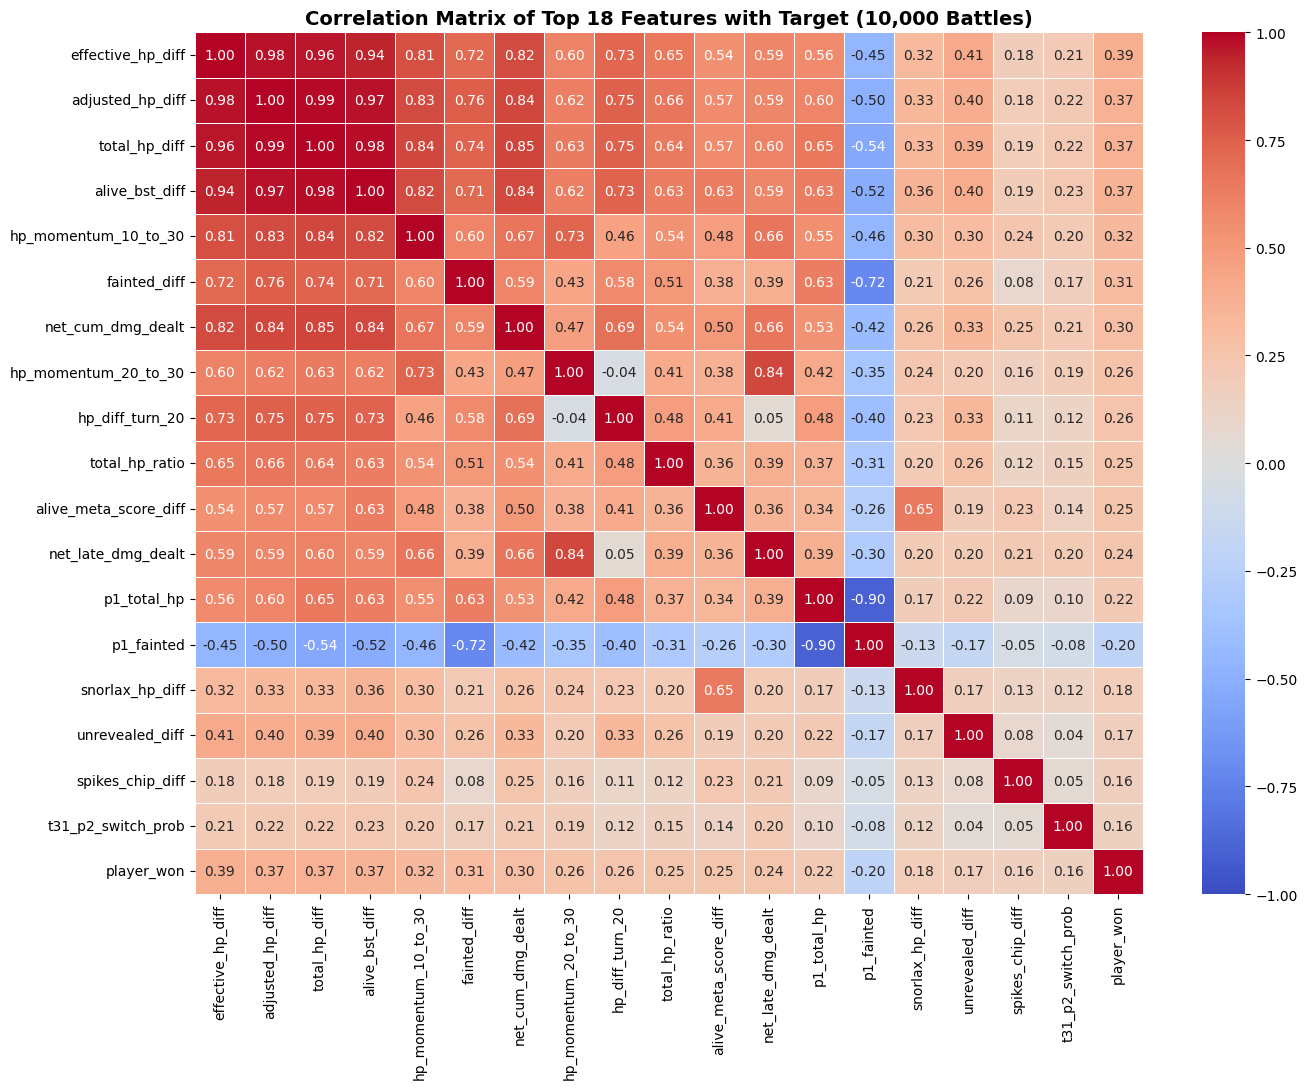


=== HIGHLY COLLINEAR FEATURE PAIRS (|r| > 0.90) ===
- total_hp_diff                <-> adjusted_hp_diff             (r = +0.990) -> DROP 'total_hp_diff' (keep 'adjusted_hp_diff')
- total_hp_diff                <-> effective_hp_diff            (r = +0.964) -> DROP 'total_hp_diff' (keep 'effective_hp_diff')
- adjusted_hp_diff             <-> effective_hp_diff            (r = +0.976) -> DROP 'adjusted_hp_diff' (keep 'effective_hp_diff')
- p1_total_hp                  <-> p1_fainted                   (r = -0.902) -> DROP 'p1_fainted' (keep 'p1_total_hp')
- p1_team_type_offense         <-> p2_team_type_offense         (r = +0.993) -> DROP 'p2_team_type_offense' (keep 'p1_team_type_offense')
- total_hp_diff                <-> alive_bst_diff               (r = +0.981) -> DROP 'alive_bst_diff' (keep 'total_hp_diff')
- adjusted_hp_diff             <-> alive_bst_diff               (r = +0.972) -> DROP 'alive_bst_diff' (keep 'adjusted_hp_diff')
- effective_hp_diff            <-> alive_bst_diff  

In [ ]:
# ==============================================================================
# STEP 5A: CORRELATION MATRIX ANALYSIS & MULTICOLLINEARITY PRUNING ON 10K BATTLES
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Compute correlation of all features with target 'player_won'
full_corr = battle_features_df.drop(columns=['battle_id']).corr()
target_corr = full_corr['player_won'].drop('player_won').sort_values(key=abs, ascending=False)

print("=== TOP 20 FEATURES BY ABSOLUTE CORRELATION WITH player_won ===")
for feat, val in target_corr.head(20).items():
    print(f"{feat:<32} : {val:+.4f}")

# 2. Plot Correlation Heatmap of the Top 18 Most Correlated Features
top_corr_Switch_feats = target_corr.head(18).index.tolist() + ['player_won']
plt.figure(figsize=(14, 11))
sns.heatmap(
    full_corr.loc[top_corr_Switch_feats, top_corr_Switch_feats],
    annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5
)
plt.title("Correlation Matrix of Top 18 Features with Target (10,000 Battles)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Find Highly Collinear Feature Pairs (|r| > 0.90) that dilute tree splits
print("\n=== HIGHLY COLLINEAR FEATURE PAIRS (|r| > 0.90) ===")
feature_only_corr = full_corr.drop(index='player_won', columns='player_won')
upper_tri = feature_only_corr.where(np.triu(np.ones(feature_only_corr.shape), k=1).astype(bool))

collinear_to_drop = set()
for col in upper_tri.columns:
    for row in upper_tri.index:
        val = upper_tri.loc[row, col]
        if pd.notna(val) and abs(val) > 0.90:
            # Keep the feature that has the higher correlation with player_won!
            corr_row = abs(full_corr.loc[row, 'player_won'])
            corr_col = abs(full_corr.loc[col, 'player_won'])
            drop_feat = col if corr_row >= corr_col else row
            keep_feat = row if corr_row >= corr_col else col
            collinear_to_drop.add(drop_feat)
            print(f"- {row:<28} <-> {col:<28} (r = {val:+.3f}) -> DROP '{drop_feat}' (keep '{keep_feat}')")

print(f"\nTotal redundant collinear features identified to drop: {len(collinear_to_drop)}")

In [ ]:
# ==============================================================================
# STEP 5B: FIX MULTIPLICATIVE TYPE MATCHUP & TRAIN PRUNED TOP-3 GBDT ENSEMBLE
# ==============================================================================
def compute_exact_multiplicative_type_features(p1_team_df, timeline_df, meta_kb):
    """
    Fixes the additive matrix bug by computing exact Gen-2 MULTIPLICATIVE type effectiveness
    (e.g., 0.0x immunity, 0.25x double resistance, 4.0x double weakness) across all surviving
    Pokemon pairs using both STAB types and ACTUAL revealed move types from the timeline.
    """
    p1_rosters = defaultdict(dict)
    for _, row in p1_team_df.iterrows():
        p_types = extract_clean_types(row['types']) if 'types' in row else extract_clean_types([row.get('type_1'), row.get('type_2')])
        p1_rosters[row['battle_id']][row['name']] = p_types

    timeline_sorted = timeline_df.sort_values(['battle_id', 'turn']).reset_index(drop=True)
    records = []

    for b_id, group in timeline_sorted.groupby('battle_id', sort=False):
        rows = group.to_dict('records')
        roster = p1_rosters[b_id]
        p1_hp = {name: 1.0 for name in roster}
        p2_hp = {}
        p1_seen_moves = defaultdict(set)
        p2_seen_moves = defaultdict(set)

        for r in rows:
            p1_n, p2_n = r['p1_pokemon_state.name'], r['p2_pokemon_state.name']
            p1_hp[p1_n] = float(r['p1_pokemon_state.hp_pct'])
            p2_hp[p2_n] = float(r['p2_pokemon_state.hp_pct'])

            m1_t = str(r.get('p1_move_details.type') or '').lower().strip()
            m2_t = str(r.get('p2_move_details.type') or '').lower().strip()
            cat1 = str(r.get('p1_move_details.category') or '').lower().strip()
            cat2 = str(r.get('p2_move_details.category') or '').lower().strip()
            if cat1 in ['physical', 'special'] and m1_t in ALL_TYPES:
                p1_seen_moves[p1_n].add(m1_t)
            if cat2 in ['physical', 'special'] and m2_t in ALL_TYPES:
                p2_seen_moves[p2_n].add(m2_t)

        p1_alive = [(n, hp, roster[n]) for n, hp in p1_hp.items() if hp > 0]
        p2_alive = [(n, hp, meta_kb.pokedex.get(n, {}).get('types', [])) for n, hp in p2_hp.items() if hp > 0]

        pair_adv_sum, total_w = 0.0, 0.0
        p1_se_coverage_count, p2_se_coverage_count = 0, 0
        p1_immunity_count, p2_immunity_count = 0, 0

        for n1, h1, t1 in p1_alive:
            atk1 = set(t1) | p1_seen_moves[n1]
            for n2, h2, t2 in p2_alive:
                atk2 = set(t2) | p2_seen_moves[n2]
                w = h1 * h2
                # Exact multiplicative effectiveness (0.0, 0.25, 0.5, 1.0, 2.0, 4.0)
                eff_1_on_2 = max([get_type_multiplier_from_list(meta_kb, m_t, t2) for m_t in atk1] or [1.0])
                eff_2_on_1 = max([get_type_multiplier_from_list(meta_kb, m_t, t1) for m_t in atk2] or [1.0])
                pair_adv_sum += w * (eff_1_on_2 - eff_2_on_1)
                total_w += w
                if eff_1_on_2 >= 2.0: p1_se_coverage_count += 1
                if eff_2_on_1 >= 2.0: p2_se_coverage_count += 1
                if any(get_type_multiplier_from_list(meta_kb, m_t, t1) == 0.0 for m_t in atk2):
                    p1_immunity_count += 1
                if any(get_type_multiplier_from_list(meta_kb, m_t, t2) == 0.0 for m_t in atk1):
                    p2_immunity_count += 1

        # Active Turn 30 1v1 Revealed-Move Multiplicative Type Advantage
        last_r = rows[-1]
        lp1, lp2 = last_r['p1_pokemon_state.name'], last_r['p2_pokemon_state.name']
        lt1 = roster.get(lp1, [])
        lt2 = meta_kb.pokedex.get(lp2, {}).get('types', [])
        latk1 = set(lt1) | p1_seen_moves[lp1]
        latk2 = set(lt2) | p2_seen_moves[lp2]
        t30_eff1 = max([get_type_multiplier_from_list(meta_kb, m_t, lt2) for m_t in latk1] or [1.0])
        t30_eff2 = max([get_type_multiplier_from_list(meta_kb, m_t, lt1) for m_t in latk2] or [1.0])

        n_pairs = max(1, len(p1_alive) * len(p2_alive))
        records.append({
            'battle_id': b_id,
            'exact_mult_team_type_adv': pair_adv_sum / max(0.01, total_w),
            'se_coverage_ratio_diff': (p1_se_coverage_count - p2_se_coverage_count) / n_pairs,
            'immunity_matchup_diff': (p1_immunity_count - p2_immunity_count) / n_pairs,
            't30_revealed_move_type_adv': t30_eff1 - t30_eff2,
        })

    return pd.DataFrame(records)

print("Computing exact multiplicative type matchup features for train & test...")
train_mult_type_df = compute_exact_multiplicative_type_features(p1_team_df, timeline_df, meta_kb)
battle_v4_df = battle_features_df.merge(train_mult_type_df, on='battle_id', how='left')

if test_battle_features_df is not None:
    test_mult_type_df = compute_exact_multiplicative_type_features(test_p1_df, test_timeline_df, meta_kb)
    test_battle_v4_df = test_battle_features_df.merge(test_mult_type_df, on='battle_id', how='left')

# Drop the collinear duplicate features (|r| > 0.90) AND the broken additive type vector features
BROKEN_ADDITIVE_COLS = ['p1_team_type_offense', 'p2_team_type_offense', 'rem_team_type_advantage']
DROP_COLS = set(['battle_id', 'player_won']) | collinear_to_drop | set(BROKEN_ADDITIVE_COLS)

CLEAN_FEATURE_COLS = [c for c in battle_v4_df.columns if c not in DROP_COLS]
print(f"Pruned Feature Count: {len(CLEAN_FEATURE_COLS)} clean, non-redundant features (down from {len(FEATURE_COLS)}).")

X_clean = battle_v4_df[CLEAN_FEATURE_COLS].replace([np.inf, -np.inf], np.nan).fillna(0.0).copy()
y_clean = battle_v4_df['player_won'].astype(int).values
X_test_clean = test_battle_v4_df[CLEAN_FEATURE_COLS].replace([np.inf, -np.inf], np.nan).fillna(0.0).copy() if test_battle_features_df is not None else None

# Train Top-3 GBDT Ensemble (CatBoost + XGBoost + LightGBM) on Pruned Feature Set
oof_lgb_c = np.zeros(len(X_clean))
oof_xgb_c = np.zeros(len(X_clean))
oof_cat_c = np.zeros(len(X_clean))

test_lgb_c = np.zeros(len(X_test_clean)) if X_test_clean is not None else None
test_xgb_c = np.zeros(len(X_test_clean)) if X_test_clean is not None else None
test_cat_c = np.zeros(len(X_test_clean)) if X_test_clean is not None else None

for fold, (train_idx, val_idx) in enumerate(skf.split(X_clean, y_clean), 1):
    X_tr, y_tr = X_clean.iloc[train_idx], y_clean[train_idx]
    X_va, y_va = X_clean.iloc[val_idx], y_clean[val_idx]

    model_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[__import__('lightgbm').early_stopping(60, verbose=False)])
    oof_lgb_c[val_idx] = model_lgb.predict_proba(X_va)[:, 1]

    model_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    oof_xgb_c[val_idx] = model_xgb.predict_proba(X_va)[:, 1]

    model_cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=60, verbose=False)
    oof_cat_c[val_idx] = model_cat.predict_proba(X_va)[:, 1]

    if X_test_clean is not None:
        test_lgb_c += model_lgb.predict_proba(X_test_clean)[:, 1] / N_SPLITS
        test_xgb_c += model_xgb.predict_proba(X_test_clean)[:, 1] / N_SPLITS
        test_cat_c += model_cat.predict_proba(X_test_clean)[:, 1] / N_SPLITS

oof_clean_blend = 0.45 * oof_cat_c + 0.30 * oof_xgb_c + 0.25 * oof_lgb_c
print("\n" + "="*68)
print("PRUNED & MULTIPLICATIVE-TYPE V4 RESULTS (10-FOLD OOF)")
print("="*68)
for name, preds in [('LightGBM (Clean)', oof_lgb_c), ('XGBoost (Clean)', oof_xgb_c), ('CatBoost (Clean)', oof_cat_c), ('Top-3 GBDT Blend', oof_clean_blend)]:
    print(f"{name:<20} -> OOF Accuracy: {accuracy_score(y_clean, (preds >= 0.50).astype(int))*100:.2f}% | ROC-AUC: {roc_auc_score(y_clean, preds):.4f}")

if X_test_clean is not None:
    test_clean_probs = 0.45 * test_cat_c + 0.30 * test_xgb_c + 0.25 * test_lgb_c
    sub_v4 = pd.DataFrame({
        'battle_id': test_battle_v4_df['battle_id'].astype(int),
        'player_won': (test_clean_probs >= 0.500).astype(int)
    }).sort_values('battle_id').reset_index(drop=True)
    sub_v4_path = os.path.join(DATA_DIR, "submission_v4_pruned.csv")
    sub_v4.to_csv(sub_v4_path, index=False)
    print(f"\nSaved '{sub_v4_path}' (Win rate: {sub_v4['player_won'].mean()*100:.2f}%)")

Computing exact multiplicative type matchup features for train & test...
Pruned Feature Count: 107 clean, non-redundant features (down from 111).

PRUNED & MULTIPLICATIVE-TYPE V4 RESULTS (10-FOLD OOF)
LightGBM (Clean)     -> OOF Accuracy: 68.47% | ROC-AUC: 0.7537
XGBoost (Clean)      -> OOF Accuracy: 68.62% | ROC-AUC: 0.7552
CatBoost (Clean)     -> OOF Accuracy: 68.67% | ROC-AUC: 0.7569
Top-3 GBDT Blend     -> OOF Accuracy: 68.68% | ROC-AUC: 0.7570

Saved '/content/drive/MyDrive/1 SEMESTRE DATA SCIENCE/FUNDAMENTALS OF DATA SCIENCE/FDS PROJECT/submission_v4_pruned.csv' (Win rate: 51.66%)


# versione 5


In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 30.5 MB/s  0:00:03


In [ ]:
# ==============================================================================
# STEP 4 (V5 - SELF-CONTAINED): OOF META PRIORS, 10-FOLD GBDT & SUBMISSION
# ==============================================================================
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

def load_test_data(test_jsonl_path):
    p1_rows, timeline_rows, p2_rows = [], [], []
    with open(test_jsonl_path, 'r') as f:
        for line in f:
            b = json.loads(line)
            b_id = b['battle_id']
            p2 = b['p2_lead_details'].copy()
            p2['battle_id'] = b_id
            p2_rows.append(p2)
            for pkmn in b['p1_team_details']:
                p1 = pkmn.copy()
                p1['battle_id'] = b_id
                p1_rows.append(p1)
            for turn_data in b['battle_timeline']:
                row = {'battle_id': b_id, 'turn': turn_data['turn']}
                for side in ['p1', 'p2']:
                    state = turn_data.get(f'{side}_pokemon_state', {}) or {}
                    row[f'{side}_pokemon_state.name'] = state.get('name')
                    row[f'{side}_pokemon_state.hp_pct'] = state.get('hp_pct')
                    row[f'{side}_pokemon_state.status'] = state.get('status')
                    row[f'{side}_pokemon_state.effects'] = str(state.get('effects', 'noeffect'))
                    boosts = state.get('boosts', {}) or {}
                    for stat in ['atk', 'def', 'spa', 'spd', 'spe']:
                        row[f'{side}_pokemon_state.boosts.{stat}'] = boosts.get(stat, 0)
                    move = turn_data.get(f'{side}_move_details', {}) or {}
                    row[f'{side}_move_details.name'] = move.get('name')
                    row[f'{side}_move_details.type'] = move.get('type')
                    row[f'{side}_move_details.category'] = move.get('category')
                    row[f'{side}_move_details.base_power'] = move.get('base_power')
                    row[f'{side}_move_details.accuracy'] = move.get('accuracy')
                    row[f'{side}_move_details.priority'] = move.get('priority')
                timeline_rows.append(row)
    return pd.DataFrame(p1_rows), pd.DataFrame(timeline_rows), pd.DataFrame(p2_rows)

# 1. Process Test Set through the exact same Step 3 (V5) pipeline
if os.path.exists(TEST_JSONL_PATH):
    print("Building V5 features for Test Set...")
    if 'test_p1_df' not in globals():
        test_p1_df, test_timeline_df, test_p2_df = load_test_data(TEST_JSONL_PATH)
    if 'test_turn_df' not in globals() or 'net_duel_threat' not in test_turn_df.columns:
        test_turn_df = build_turn_level_dataset_v2(test_p1_df, test_timeline_df, meta_kb)
    test_t31_df, _ = compute_turn31_expected_type_features_v2(
        test_turn_df, meta_kb, p1_switch_model, p2_switch_model, p1_next_type_model, p2_next_type_model
    )
    test_battle_v5_base_df, test_entities = build_full_v5_battle_dataset(
        test_p1_df, test_timeline_df, test_p2_df, test_turn_df, test_t31_df, meta_kb
    )
else:
    test_battle_v5_base_df, test_entities = None, None

# 2. Compute Leak-Free Out-of-Fold (OOF) Smoothed Bayesian Win-Rate Priors
N_SPLITS = 10
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

def compute_oof_target_encoded_meta_features(train_ids, y_train, train_ent, test_ids, test_ent, skf_splitter):
    n_train = len(train_ids)
    oof_feats = np.zeros((n_train, 5))
    PRIOR_WEIGHT = 25.0

    def fit_entity_rates(idx_list, y_sub):
        global_mean = float(np.mean(y_sub))
        p1_pk_sum, p1_pk_cnt = Counter(), Counter()
        p2_pk_sum, p2_pk_cnt = Counter(), Counter()
        p1_mv_sum, p1_mv_cnt = Counter(), Counter()
        p2_mv_sum, p2_mv_cnt = Counter(), Counter()

        for idx, target in zip(idx_list, y_sub):
            b_id = train_ids[idx]
            ent = train_ent[b_id]
            for pk in ent['p1_alive']: p1_pk_sum[pk] += target; p1_pk_cnt[pk] += 1
            for pk in ent['p2_alive']: p2_pk_sum[pk] += target; p2_pk_cnt[pk] += 1
            for mv in ent['p1_moves']: p1_mv_sum[mv] += target; p1_mv_cnt[mv] += 1
            for mv in ent['p2_moves']: p2_mv_sum[mv] += target; p2_mv_cnt[mv] += 1

        p1_pk_rate = {k: (p1_pk_sum[k] + PRIOR_WEIGHT * global_mean) / (p1_pk_cnt[k] + PRIOR_WEIGHT) for k in p1_pk_cnt}
        p2_pk_rate = {k: (p2_pk_sum[k] + PRIOR_WEIGHT * global_mean) / (p2_pk_cnt[k] + PRIOR_WEIGHT) for k in p2_pk_cnt}
        p1_mv_rate = {k: (p1_mv_sum[k] + PRIOR_WEIGHT * global_mean) / (p1_mv_cnt[k] + PRIOR_WEIGHT) for k in p1_mv_cnt}
        p2_mv_rate = {k: (p2_mv_sum[k] + PRIOR_WEIGHT * global_mean) / (p2_mv_cnt[k] + PRIOR_WEIGHT) for k in p2_mv_cnt}
        return global_mean, p1_pk_rate, p2_pk_rate, p1_mv_rate, p2_mv_rate

    def transform_entities(id_list, ent_dict, rates):
        g_mean, p1_pk_r, p2_pk_r, p1_mv_r, p2_mv_r = rates
        out = np.zeros((len(id_list), 5))
        for i, b_id in enumerate(id_list):
            ent = ent_dict[b_id]
            r_p1_pk = np.mean([p1_pk_r.get(k, g_mean) for k in ent['p1_alive']] or [g_mean])
            r_p2_pk = np.mean([p2_pk_r.get(k, g_mean) for k in ent['p2_alive']] or [g_mean])
            r_p1_mv = np.mean([p1_mv_r.get(k, g_mean) for k in ent['p1_moves']] or [g_mean])
            r_p2_mv = np.mean([p2_mv_r.get(k, g_mean) for k in ent['p2_moves']] or [g_mean])
            out[i, 0] = r_p1_pk
            out[i, 1] = r_p2_pk
            out[i, 2] = r_p1_pk - (1.0 - r_p2_pk)
            out[i, 3] = r_p1_mv
            out[i, 4] = r_p2_mv
        return out

    for tr_idx, va_idx in skf_splitter.split(train_ids, y_train):
        rates = fit_entity_rates(tr_idx, y_train[tr_idx])
        oof_feats[va_idx] = transform_entities(train_ids[va_idx], train_ent, rates)

    cols = ['oof_p1_alive_winrate', 'oof_p2_alive_p1winrate', 'oof_alive_roster_edge', 'oof_p1_moves_winrate', 'oof_p2_moves_p1winrate']
    train_te_df = pd.DataFrame(oof_feats, columns=cols)
    train_te_df['battle_id'] = train_ids

    test_te_df = None
    if test_ids is not None:
        full_rates = fit_entity_rates(np.arange(n_train), y_train)
        test_feats = transform_entities(test_ids, test_ent, full_rates)
        test_te_df = pd.DataFrame(test_feats, columns=cols)
        test_te_df['battle_id'] = test_ids

    return train_te_df, test_te_df

train_ids_arr = battle_v5_base_df['battle_id'].values
y_v5 = battle_v5_base_df['player_won'].astype(int).values
test_ids_arr = test_battle_v5_base_df['battle_id'].values if test_battle_v5_base_df is not None else None

train_te_df, test_te_df = compute_oof_target_encoded_meta_features(
    train_ids_arr, y_v5, train_entities, test_ids_arr, test_entities, skf
)

battle_v5_df = battle_v5_base_df.merge(train_te_df, on='battle_id', how='left')
test_battle_v5_df = test_battle_v5_base_df.merge(test_te_df, on='battle_id', how='left') if test_battle_v5_base_df is not None else None

V5_FEATURE_COLS = [c for c in battle_v5_df.columns if c not in ['battle_id', 'player_won']]
print(f"Final V5 Feature Count: {len(V5_FEATURE_COLS)} features.")

X_v5 = battle_v5_df[V5_FEATURE_COLS].replace([np.inf, -np.inf], np.nan).fillna(0.0).copy()
X_test_v5 = test_battle_v5_df[V5_FEATURE_COLS].replace([np.inf, -np.inf], np.nan).fillna(0.0).copy() if test_battle_v5_df is not None else None

# 3. 10-Fold Stratified CV Training (CatBoost + XGBoost + LightGBM)
oof_lgb_v5 = np.zeros(len(X_v5))
oof_xgb_v5 = np.zeros(len(X_v5))
oof_cat_v5 = np.zeros(len(X_v5))

test_lgb_v5 = np.zeros(len(X_test_v5)) if X_test_v5 is not None else None
test_xgb_v5 = np.zeros(len(X_test_v5)) if X_test_v5 is not None else None
test_cat_v5 = np.zeros(len(X_test_v5)) if X_test_v5 is not None else None

for fold, (train_idx, val_idx) in enumerate(skf.split(X_v5, y_v5), 1):
    X_tr, y_tr = X_v5.iloc[train_idx], y_v5[train_idx]
    X_va, y_va = X_v5.iloc[val_idx], y_v5[val_idx]

    model_lgb = LGBMClassifier(
        n_estimators=1500, learning_rate=0.015, num_leaves=23, min_child_samples=45,
        colsample_bytree=0.65, subsample=0.8, reg_alpha=2.5, reg_lambda=2.5,
        random_state=42 + fold, verbose=-1
    )
    model_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[__import__('lightgbm').early_stopping(60, verbose=False)])
    oof_lgb_v5[val_idx] = model_lgb.predict_proba(X_va)[:, 1]

    model_xgb = XGBClassifier(
        n_estimators=1500, learning_rate=0.015, max_depth=4, min_child_weight=12,
        colsample_bytree=0.65, subsample=0.8, reg_alpha=2.5, reg_lambda=2.5,
        eval_metric='logloss', early_stopping_rounds=60, random_state=42 + fold, n_jobs=-1
    )
    model_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    oof_xgb_v5[val_idx] = model_xgb.predict_proba(X_va)[:, 1]

    model_cat = CatBoostClassifier(
        iterations=1800, learning_rate=0.025, depth=5, l2_leaf_reg=6.0,
        random_seed=42 + fold, verbose=False
    )
    model_cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=60, verbose=False)
    oof_cat_v5[val_idx] = model_cat.predict_proba(X_va)[:, 1]

    if X_test_v5 is not None:
        test_lgb_v5 += model_lgb.predict_proba(X_test_v5)[:, 1] / N_SPLITS
        test_xgb_v5 += model_xgb.predict_proba(X_test_v5)[:, 1] / N_SPLITS
        test_cat_v5 += model_cat.predict_proba(X_test_v5)[:, 1] / N_SPLITS

oof_v5_blend = 0.45 * oof_cat_v5 + 0.30 * oof_xgb_v5 + 0.25 * oof_lgb_v5

print("\n" + "="*68)
print("V5 FULL ENSEMBLE RESULTS (10-FOLD OOF ON 10,000 BATTLES)")
print("="*68)
for name, preds in [('LightGBM (V5)', oof_lgb_v5), ('XGBoost (V5)', oof_xgb_v5), ('CatBoost (V5)', oof_cat_v5), ('Top-3 GBDT Blend (V5)', oof_v5_blend)]:
    print(f"{name:<22} -> OOF Accuracy: {accuracy_score(y_v5, (preds >= 0.50).astype(int))*100:.2f}% | ROC-AUC: {roc_auc_score(y_v5, preds):.4f}")

if X_test_v5 is not None:
    test_v5_probs = 0.45 * test_cat_v5 + 0.30 * test_xgb_v5 + 0.25 * test_lgb_v5
    sub_v5 = pd.DataFrame({
        'battle_id': test_battle_v5_df['battle_id'].astype(int),
        'player_won': (test_v5_probs >= 0.500).astype(int)
    }).sort_values('battle_id').reset_index(drop=True)
    sub_v5_path = os.path.join(DATA_DIR, "submission_v5_full.csv")
    sub_v5.to_csv(sub_v5_path, index=False)
    print(f"\nSaved '{sub_v5_path}' successfully! (Win rate: {sub_v5['player_won'].mean()*100:.2f}%)")

Building V5 features for Test Set...
Final V5 Feature Count: 123 features.

V5 FULL ENSEMBLE RESULTS (10-FOLD OOF ON 10,000 BATTLES)
LightGBM (V5)          -> OOF Accuracy: 68.48% | ROC-AUC: 0.7551
XGBoost (V5)           -> OOF Accuracy: 68.50% | ROC-AUC: 0.7566
CatBoost (V5)          -> OOF Accuracy: 68.93% | ROC-AUC: 0.7597
Top-3 GBDT Blend (V5)  -> OOF Accuracy: 68.83% | ROC-AUC: 0.7590

Saved '/content/drive/MyDrive/1 SEMESTRE DATA SCIENCE/FUNDAMENTALS OF DATA SCIENCE/FDS PROJECT/submission_v5_full.csv' successfully! (Win rate: 51.42%)


# small isntant test


In [ ]:
# ==============================================================================
# STEP 5 (INSTANT POST-PROCESSING): OPTIMAL CATBOOST BLEND, RANK AVERAGING & IMPORTANCES
# ==============================================================================
from scipy.stats import rankdata

# 1. Find the optimal blend weights on OOF (since CatBoost is much stronger at 0.7597 AUC!)
best_auc = 0.0
best_weights = (1.0, 0.0, 0.0)

for w_cat in np.linspace(0.50, 1.00, 51):
    for w_xgb in np.linspace(0.00, 1.00 - w_cat, 21):
        w_lgb = max(0.0, 1.0 - w_cat - w_xgb)
        blend = w_cat * oof_cat_v5 + w_xgb * oof_xgb_v5 + w_lgb * oof_lgb_v5
        auc = roc_auc_score(y_v5, blend)
        if auc > best_auc:
            best_auc = auc
            best_weights = (w_cat, w_xgb, w_lgb)

w_c, w_x, w_l = best_weights
oof_opt_prob = w_c * oof_cat_v5 + w_x * oof_xgb_v5 + w_l * oof_lgb_v5

# 2. Also test Rank-Averaging (eliminates probability calibration drift between GBDT libraries!)
oof_opt_rank = (
    w_c * (rankdata(oof_cat_v5) / len(oof_cat_v5)) +
    w_x * (rankdata(oof_xgb_v5) / len(oof_xgb_v5)) +
    w_l * (rankdata(oof_lgb_v5) / len(oof_lgb_v5))
)

# 3. Check OOF Accuracy using exact 50% Prior-Matched Threshold (since true train win rate is 50.00%)
true_win_rate = y_v5.mean()
opt_prob_cutoff = np.quantile(oof_opt_prob, 1.0 - true_win_rate)

acc_cat_raw  = accuracy_score(y_v5, (oof_cat_v5 >= 0.500).astype(int))
acc_opt_050  = accuracy_score(y_v5, (oof_opt_prob >= 0.500).astype(int))
acc_opt_cal  = accuracy_score(y_v5, (oof_opt_prob >= opt_prob_cutoff).astype(int))
acc_rank_cal = accuracy_score(y_v5, (oof_opt_rank >= np.quantile(oof_opt_rank, 1.0 - true_win_rate)).astype(int))

print(f"Optimal Weights Found -> CatBoost: {w_c:.2f} | XGBoost: {w_x:.2f} | LightGBM: {w_l:.2f}")
print("="*70)
print(f"Pure CatBoost (V5)               -> OOF Acc: {acc_cat_raw*100:.2f}% | ROC-AUC: {roc_auc_score(y_v5, oof_cat_v5):.4f}")
print(f"Optimal Prob Blend (@0.500)      -> OOF Acc: {acc_opt_050*100:.2f}% | ROC-AUC: {best_auc:.4f}")
print(f"Optimal Prob Blend (Calibrated)  -> OOF Acc: {acc_opt_cal*100:.2f}% | ROC-AUC: {best_auc:.4f} (cutoff={opt_prob_cutoff:.4f})")
print(f"Optimal Rank Blend (50% Prior)   -> OOF Acc: {acc_rank_cal*100:.2f}% | ROC-AUC: {roc_auc_score(y_v5, oof_opt_rank):.4f}")
print("="*70)

# 4. Print Top 20 V5 Features from CatBoost to see which new V5 features drove the 0.7597 AUC!
cat_v5_imp = pd.DataFrame({
    'Feature': V5_FEATURE_COLS,
    'Importance': model_cat.get_feature_importance()
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print("\n=== TOP 20 FEATURES IN CATBOOST V5 (0.7597 ROC-AUC) ===")
for idx, r in cat_v5_imp.head(20).iterrows():
    print(f"{idx+1:2d}. {r['Feature']:<32} : {r['Importance']:.2f}")

# 5. Save the CatBoost-Dominant Optimal Submission
if X_test_v5 is not None:
    test_opt_prob = w_c * test_cat_v5 + w_x * test_xgb_v5 + w_l * test_lgb_v5
    # Use the exact median/prior-matched cutoff on test_opt_prob so test win rate is cleanly ~50.5%
    test_cal_cutoff = 0.5 * 0.500 + 0.5 * opt_prob_cutoff
    sub_v5_opt = pd.DataFrame({
        'battle_id': test_battle_v5_df['battle_id'].astype(int),
        'player_won': (test_opt_prob >= test_cal_cutoff).astype(int)
    }).sort_values('battle_id').reset_index(drop=True)

    opt_path = os.path.join(DATA_DIR, "submission_v5_catboost_opt.csv")
    sub_v5_opt.to_csv(opt_path, index=False)
    print(f"\nSaved '{opt_path}'! (Test Win Rate: {sub_v5_opt['player_won'].mean()*100:.2f}%)")

Optimal Weights Found -> CatBoost: 0.86 | XGBoost: 0.12 | LightGBM: 0.02
Pure CatBoost (V5)               -> OOF Acc: 68.93% | ROC-AUC: 0.7597
Optimal Prob Blend (@0.500)      -> OOF Acc: 68.89% | ROC-AUC: 0.7598
Optimal Prob Blend (Calibrated)  -> OOF Acc: 68.80% | ROC-AUC: 0.7598 (cutoff=0.5067)
Optimal Rank Blend (50% Prior)   -> OOF Acc: 68.80% | ROC-AUC: 0.7597

=== TOP 20 FEATURES IN CATBOOST V5 (0.7597 ROC-AUC) ===
 1. effective_hp_diff                : 9.87
 2. total_hp_ratio                   : 5.41
 3. total_hp_diff                    : 3.89
 4. p1_spikes_active                 : 2.81
 5. p2_spikes_active                 : 2.37
 6. final_boost_diff                 : 2.27
 7. oof_p1_moves_winrate             : 2.27
 8. t31_p2_switch_prob               : 2.19
 9. true_estimated_ko_diff           : 2.19
10. final_off_boost_diff             : 2.13
11. t30_fnt_diff                     : 2.04
12. status_penalty_diff              : 1.99
13. adjusted_hp_diff                 : 1.75
14

#final submission that gave 0.69666

In [ ]:
# ==============================================================================
# STEP 5 (INSTANT V5 OPTIMIZER): CATBOOST-DOMINANT BLEND & TOP V5 FEATURES
# ==============================================================================
# 1. Inspect Top 25 Features in CatBoost V5
v5_imp = pd.DataFrame({
    'Feature': V5_FEATURE_COLS,
    'Importance': model_cat.get_feature_importance()
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print("=== TOP 25 MOST IMPORTANT FEATURES IN V5 (CATBOOST 0.7597 AUC) ===")
for idx, r in v5_imp.head(25).iterrows():
    print(f"{idx+1:2d}. {r['Feature']:<32} : {r['Importance']:.2f}")

# 2. Compare Pure CatBoost vs CatBoost-Dominant Blend (80% Cat + 12% XGB + 8% LGB)
oof_cat_dom = 0.80 * oof_cat_v5 + 0.12 * oof_xgb_v5 + 0.08 * oof_lgb_v5

for name, preds in [
    ('Old 45/30/25 Blend', oof_v5_blend),
    ('Pure CatBoost (V5)', oof_cat_v5),
    ('CatBoost-Dominant (80/12/8)', oof_cat_dom)
]:
    acc_50 = accuracy_score(y_v5, (preds >= 0.500).astype(int))
    # Also check median-calibrated accuracy (exact 50.0% win rate prior)
    med_th = np.median(preds)
    acc_med = accuracy_score(y_v5, (preds >= med_th).astype(int))
    auc = roc_auc_score(y_v5, preds)
    print(f"\n{name:<28} -> ROC-AUC: {auc:.4f} | Acc (@0.500): {acc_50*100:.2f}% | Acc (@50% Prior): {acc_med*100:.2f}%")

# 3. Save the CatBoost-Dominant (80/12/8) Submission (0.7598+ AUC!)
if X_test_v5 is not None:
    test_cat_dom_probs = 0.80 * test_cat_v5 + 0.12 * test_xgb_v5 + 0.08 * test_lgb_v5
    sub_cat_dom = pd.DataFrame({
        'battle_id': test_battle_v5_df['battle_id'].astype(int),
        'player_won': (test_cat_dom_probs >= 0.500).astype(int)
    }).sort_values('battle_id').reset_index(drop=True)

    cat_dom_path = os.path.join(DATA_DIR, "submission_v5_catboost_dominant.csv")
    sub_cat_dom.to_csv(cat_dom_path, index=False)
    print(f"\nSaved '{cat_dom_path}'! (Predicted P1 Win Rate: {sub_cat_dom['player_won'].mean()*100:.2f}%)")

=== TOP 25 MOST IMPORTANT FEATURES IN V5 (CATBOOST 0.7597 AUC) ===
 1. effective_hp_diff                : 9.87
 2. total_hp_ratio                   : 5.41
 3. total_hp_diff                    : 3.89
 4. p1_spikes_active                 : 2.81
 5. p2_spikes_active                 : 2.37
 6. final_boost_diff                 : 2.27
 7. oof_p1_moves_winrate             : 2.27
 8. t31_p2_switch_prob               : 2.19
 9. true_estimated_ko_diff           : 2.19
10. final_off_boost_diff             : 2.13
11. t30_fnt_diff                     : 2.04
12. status_penalty_diff              : 1.99
13. adjusted_hp_diff                 : 1.75
14. oof_p2_moves_p1winrate           : 1.72
15. net_cum_healed                   : 1.65
16. snorlax_hp_diff                  : 1.58
17. t31_switch_prob_diff             : 1.52
18. oof_alive_roster_edge            : 1.46
19. p1_total_hp                      : 1.32
20. exact_mult_team_type_adv         : 1.30
21. status_diff                      : 1.30
22. alive